# 고립·은둔 청년의 복지 접근 병목과 비대면 연결 모델 「반 걸음」

## 어떤 문제를 다루는가

- 도움을 원하는 청년이 복지 정보를 찾고 신청하는 과정에서 어디에 막히는지 살펴봄
- 청년에게 필요한 지원, 서비스의 신청·이용 방식, 정보의 충분함, 검색 결과를 함께 분석함
- 「반 걸음」은 청년이 자기 상황을 일상어로 적으면 필요한 지원을 찾고 신청 경로를 원문과 함께 보여주는 서비스임
- 현재 모델의 정보 추출·검색·추천 성능을 계속 개선 중임

## 세 분석의 역할

| 분석 | 확인할 질문 | 분석 방법 |
|---|---|---|
| Q1 지원 수요와 이용 조건 | 필요한 지원에 해당하는 서비스가 있고, 집에서 신청·이용할 수 있는가? | 조사 응답과 복지서비스의 지원내용·신청·이용 조건 비교 |
| Q2 정보의 충분함 | 한 사이트만 보고 신청에 필요한 정보를 알 수 있는가? | 한국사회보장정보원과 보조금24의 동일사업 후보 정보 비교 |
| Q3 검색과 추천 | 같은 상황을 일상어로 적어도 도움이 되는 서비스를 찾는가? | 일상어·행정어 검색 비교와 사람 판정을 통한 성능 평가 |

## 표와 그림을 읽는 기준

- 수요는 조사에 참여한 사람의 응답 비율, 공급은 등록된 서비스 건수임
- 서비스 건수에는 지원 정원·예산·실제 이용 인원이 반영되지 않음
- 정보가 부족해 판정할 수 없는 항목은 각 표에 적힌 분모 기준에 따라 처리함
- 서비스 설명으로 만든 분류는 개인의 신청 자격과 실제 이용 가능성을 추가 확인해야 함

## 분석 흐름

- 조사에서 필요한 지원 확인 → 서비스의 신청·이용 조건 분석 → 정보 부족과 검색 문제 확인 → 「반 걸음」의 연결 방식과 성능 평가

# 1. 연구 배경

- 거의 집에만 머무는 19~34세 청년 비율이 2022년 2.4%에서 2024년 5.2%로 증가함
- 고립·은둔 징후가 있는 청년 규모는 한국보건사회연구원 추정 기준 최대 약 54만 명임
- 2024년 8월 인천·울산·충북·전북에서 청년미래센터 시범사업을 시작함
- 2025년 「가족돌봄 등 위기아동·청년 지원에 관한 법률」 제정으로 지원 근거를 마련함
- 신청주의에서는 정보 탐색과 연락·방문을 당사자가 시작해야 하므로, 이 과정에서 제도를 모르거나 신청하지 못할 수 있음

## 분석 자료

| 자료 | 출처 | 분석에 쓰는 내용 |
|---|---|---|
| 공개 조사 결과 | 2023 고립·은둔 청년 실태조사, 2024 청년의 삶 실태조사 | 도움 경험과 지원 필요도 |
| 조사 응답 자료 | 2023 실태조사에서 연구 기준에 맞춰 구성한 은둔·고립 표본 | 지원 영역별 필요도와 집단 차이 |
| 복지서비스 자료 | 한국사회보장정보원(SSIS)의 중앙부처·지자체 서비스 | 지원 대상·내용과 신청·이용 방식 |
| 플랫폼 비교 자료 | 한국사회보장정보원과 보조금24 | 같은 사업으로 추정되는 서비스의 정보 비교 |
| 검색 평가 자료 | 일상어·행정어 질의와 가상 상황 카드, 사람의 관련성 판정 | 검색 결과의 겹침과 추천 적합성 |


In [1]:
import json
import textwrap
import numpy as np
from io import BytesIO
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/preprocess/ssis_master.py").is_file()
     and (path / "ai/pipeline.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("저장소 루트 또는 notebooks 폴더에서 실행해 주세요.")
sys.path.insert(0, str(ROOT))

from src.gap_index.q1_supply import demand_table, load_master
from src.preprocess.keywords import APP_DOMAIN_DEFS_V3, APP_DOMAIN_MAP_V3, APP_DOMAINS_V3, Q21_LABELS

OUTPUT = ROOT / "outputs/final_bangeoreum"
TABLES = OUTPUT / "tables"
MASTER_PATH = "data/processed/services_master.csv"
PAPER_REV = "0d86a1d94e2ae3c007e39e078755b88c160fd4ef"

# STEP 01의 한글 글꼴 선택과 CSV 저장 방식 사용
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
korean_fonts = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans KR", "Noto Sans CJK KR"]
plt.rcParams.update({
    "font.family": [name for name in korean_fonts if name in available_fonts][:1] or ["sans-serif"],
    "axes.unicode_minus": False,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def save_table(table, filename):
    TABLES.mkdir(parents=True, exist_ok=True)
    table.to_csv(TABLES / filename, index=False, encoding="utf-8-sig")




# STEP Q1·Q2·Q3의 공통 색상과 캡션 저장 방식 사용
INK, INK2, MUTED = "#1f1f1d", "#52514e", "#8a8984"
C_HIKI, C_ISO = "#2a78d6", "#eb6834"
C_M4, C_M34 = "#1d4f91", "#86b4ec"
C_DARK, C_MID, C_LIGHT, C_ORANGE, C_GRAY = "#1d4f91", "#2a78d6", "#86b4ec", "#eb6834", "#c9c8c3"
SHORT = {
    "q21_01": "머물 수 있는 공간", "q21_02": "일상생활 회복", "q21_03": "혼자 하는 취미·문화·체육",
    "q21_04": "같이 하는 취미·문화·체육", "q21_05": "전문가 상담·치료",
    "q21_06": "또래·멘토 상담·지지", "q21_07": "교육·학습",
    "q21_08": "취업(정보)·일 경험", "q21_09": "공동생활", "q21_10": "경제적 지원",
}
MEAS_KO = {"very_needed_4": "매우 필요(4)", "needed_3_4": "필요(3+4)"}
plt.rcParams.update({
    "font.size": 10, "axes.labelcolor": INK2, "axes.edgecolor": "#a3a29d",
    "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 9,
})


def save_figure(fig, filename, caption):
    folder = OUTPUT / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    fig.canvas.draw()
    bounds = fig.get_tightbbox(fig.canvas.get_renderer())
    fig.text(bounds.x0 / fig.get_figwidth(),
             bounds.y0 / fig.get_figheight() - 0.035,
             textwrap.fill(caption, width=100),
             ha="left", va="top", fontsize=8, color=INK2, transform=fig.transFigure)
    target = folder / filename
    fig.savefig(target, dpi=300, bbox_inches="tight", facecolor="white", pad_inches=0.2)
    plt.close(fig)
    display(Image(filename=str(target), width=1050))

# 2. 수요 측 분석

## 표 1. 고립·은둔 청년 관련 주요 지표

| 지표 | 수치 | 출처·분모 |
|---|---|---|
| 거의 집에만 있는 청년 | 5.2% (2022년 2.4%) | 2024 청년의 삶 실태조사, 19~34세 |
| 고립·은둔 징후 청년 규모 | 최대 약 54만 명 | 한국보건사회연구원 추정 |
| 현재 상태에서 벗어나기를 원함 | 80.8% | 2023 고립·은둔 청년 실태조사 |
| 도움을 받은 경험 없음 | 56% | 2023 실태조사, 미경험 사유 1순위 정보 부재(28.5%) |
| 자살 생각 경험 | 75.4% | 2023 실태조사, 해당 문항 응답자 8,436명 |
| 필요한 지원 | 경제 88.7%, 취업·일 경험 82.2%, 혼자 하는 활동 81.7% | 2023 실태조사 공개 집계, 복수 응답 |

- 2023년 전국 실태조사 전체 응답 규모는 21,360명이며 지표별 분모는 문항에 따라 다름
- 회복과 경제·취업 지원 수요가 높고, 도움 경험이 없는 응답자에게 정보 부재가 가장 많이 보고됨
- 혼자 하는 활동 지원 수요는 대면을 전제로 하지 않는 시작 경로가 필요함을 시사함
- 위기 관련 응답 비중을 설계 단계의 위기 확인 근거로 사용함

## 응답 자료에서 지원 필요도 확인

- 연구 기준에 맞춰 구성한 은둔 표본 4,448명의 응답을 집계함
- 지원 필요도는 조사에서 경제·취업·상담 등 10개 영역의 필요 정도를 물은 문항(Q21)을 사용함
- 문항별 유효 응답에서 ‘약간 필요’와 ‘매우 필요’를 합산한 비가중 비율임
- 표 1은 공개 집계, 아래 표는 연구에서 별도로 구성한 표본의 결과임

In [2]:
demand = demand_table(ROOT / "data/processed/demand_2023_hikikomori.csv")
q21 = (
    demand.loc[demand["measure"].eq("needed_3_4"),
               ["area_label", "n_respondents", "k", "rate"]]
    .sort_values("rate", ascending=False, ignore_index=True)
    .rename(columns={"area_label": "지원 영역", "n_respondents": "유효 응답자 수", "k": "필요 응답자 수"})
)
q21["필요 응답 비율(%)"] = 100 * q21.pop("rate")
save_table(q21, "q21_support_needs.csv")
display(q21.round({"필요 응답 비율(%)": 1}))

,지원 영역,유효 응답자 수,필요 응답자 수,필요 응답 비율(%)
0,경제적 지원,4446,4023,90.5
1,취업(정보)·일 경험 지원,4446,3788,85.2
2,일상생활 회복 지원,4446,3640,81.9
3,혼자 하는 취미·문화·체육활동 지원,4444,3613,81.3
4,교육·학습 지원,4446,3504,78.8
5,눈치 보지 않고 들러서 머물 수 있는 공간,4446,3463,77.9
6,전문가에 의한 상담·치료,4445,3148,70.8
7,같이 하는 취미·문화·체육활동 지원,4446,2598,58.4
8,공동생활(규칙적인 생활 등),4447,2208,49.7
9,"또래, 멘토 등에 의한 상담·지지",4446,1924,43.3


# 3. 공급 측 분석

- 2026년 10월 30일 수집한 SSIS 중앙부처·지자체 서비스 목록·상세를 서비스 ID 단위로 집계함
- 온라인 신청 필드와 신청방법·지원내용·지원대상 원문을 규칙으로 분류하고 근거 문장을 보존함
- 논문의 청년 대상 집단은 서비스의 지원 연령에 19~34세가 포함되는지에 따라 구성함

## 표 2. 서비스 접근성 라벨 정의

| 라벨 | 값 | 판정 근거 |
|---|---|---|
| 신청 방식 | 온라인 / 전화·기관 경유 / 방문 | 온라인 신청, 전화·우편·대리 등 경로, 방문 또는 필수 면접 |
| 비대면 완결성 | 완결 / 부분 / 불가 | 신청과 이용 모두 비대면 / 한 단계만 비대면 / 두 단계 모두 대면 |
| 청년 대상 여부 | 예 / 아니오 / 판정 불가 | 원문에서 추출한 연령 범위와 19~34세의 겹침 |
| 고립·은둔 명시 | 예 / 아니오 | 서비스명·설명·대상 등 원문의 관련 표현 |

- 온라인 신청 범주에는 온라인으로 신청이 끝나는 서비스와 별도 신청이 필요 없는 서비스를 포함함
- 방문 범주에는 기관 방문과 필수 면접으로 분류된 서비스를 포함함
- 방문만 안내된 기록은 실제로 다른 경로를 이용할 수 있는지 추가 확인이 필요함
- 설명문의 표현과 구조화된 항목에 규칙을 적용해 분류했으며, 기준을 보완했을 때의 차이는 부록에서 확인함

In [3]:
# 논문 수치와 일치하는 라벨 버전을 Git에서 읽기
snapshot = subprocess.run(
    ["git", "show", f"{PAPER_REV}:{MASTER_PATH}"],
    cwd=ROOT, capture_output=True, check=False,
)
if snapshot.returncode:
    raise FileNotFoundError(f"Git 이력에서 논문 자료 버전 {PAPER_REV[:7]}을 찾을 수 없습니다.")

paper_master = pd.read_csv(BytesIO(snapshot.stdout), dtype=str, keep_default_na=False, encoding="utf-8-sig")
assert len(paper_master) == 5_288 and paper_master["servId"].is_unique
assert paper_master["source"].value_counts().to_dict() == {"local": 4_827, "central": 461}

# STEP 01의 출처별 값 빈도 집계에 판정 가능 분모와 논문의 집단 정의를 적용
def access_summary(master, youth_column):
    rows = []
    groups = {
        "전체": master,
        "중앙부처": master.loc[master["source"].eq("central")],
        "지자체": master.loc[master["source"].eq("local")],
        "청년 대상": master.loc[master[youth_column].eq("예")],
    }
    for group, services in groups.items():
        applications = services["apply_barrier"].value_counts()
        remote = services["remote_complete"].value_counts()
        rows.append({
            "집단": group,
            "서비스 수": len(services),
            "신청 판정 가능": applications.reindex(["0", "1", "2", "3"], fill_value=0).sum(),
            "온라인": applications.get("0", 0),
            "전화·기관 경유": applications.get("1", 0),
            "방문·면접": applications.get("2", 0) + applications.get("3", 0),
            "비대면 판정 가능": remote.reindex(["0", "1", "2"], fill_value=0).sum(),
            "비대면 완결": remote.get("2", 0),
            "고립·은둔 명시": services["isolation_explicit"].eq("예").sum(),
        })

    table = pd.DataFrame(rows)
    for column in ("온라인", "전화·기관 경유", "방문·면접"):
        table[f"{column}(%)"] = 100 * table[column] / table["신청 판정 가능"]
    table["비대면 완결(%)"] = 100 * table["비대면 완결"] / table["비대면 판정 가능"]
    table["고립·은둔 명시(%)"] = 100 * table["고립·은둔 명시"] / table["서비스 수"]
    return table

access = access_summary(paper_master, "elig_youth_v1")
save_table(access, "service_accessibility.csv")

## 표 3. 집단별 서비스 접근성 지표

- 신청 방식과 비대면 완결성의 판정 불가 건을 각각의 분모에서 제외함
- 비율은 가중치 없는 서비스 비율이며, 청년 대상은 전체에 포함되는 하위 집단임

In [4]:
table3 = access.set_index("집단")
show_columns = ["서비스 수", "신청 판정 가능", "방문·면접(%)", "온라인(%)",
                "비대면 판정 가능", "비대면 완결", "비대면 완결(%)",
                "고립·은둔 명시", "고립·은둔 명시(%)"]
precision = {"방문·면접(%)": 1, "온라인(%)": 1, "비대면 완결(%)": 1, "고립·은둔 명시(%)": 2}
display(table3[show_columns].round(precision).T.style
        .format("{:,.0f}", subset=pd.IndexSlice[[c for c in show_columns if c not in precision], :])
        .format("{:.1f}%", subset=pd.IndexSlice[[c for c, digits in precision.items() if digits == 1], :])
        .format("{:.2f}%", subset=pd.IndexSlice[["고립·은둔 명시(%)"], :]))

집단,전체,중앙부처,지자체,청년 대상
서비스 수,"5,288",461,"4,827",608
신청 판정 가능,"4,532",397,"4,135",579
방문·면접(%),58.8%,83.4%,56.5%,44.2%
온라인(%),29.7%,16.1%,31.0%,48.4%
비대면 판정 가능,"3,727",325,"3,402",514
비대면 완결,"1,255",54,"1,201",250
비대면 완결(%),33.7%,16.6%,35.3%,48.6%
고립·은둔 명시,19,2,17,6
고립·은둔 명시(%),0.36%,0.43%,0.35%,0.99%


## 그림 1. 복지서비스 신청 방식 분포

- 각 집단에서 신청 방식 판정이 가능한 서비스만 사용함
- 방문·면접에는 방문 신청과 필수 면접으로 분류된 서비스가 포함됨

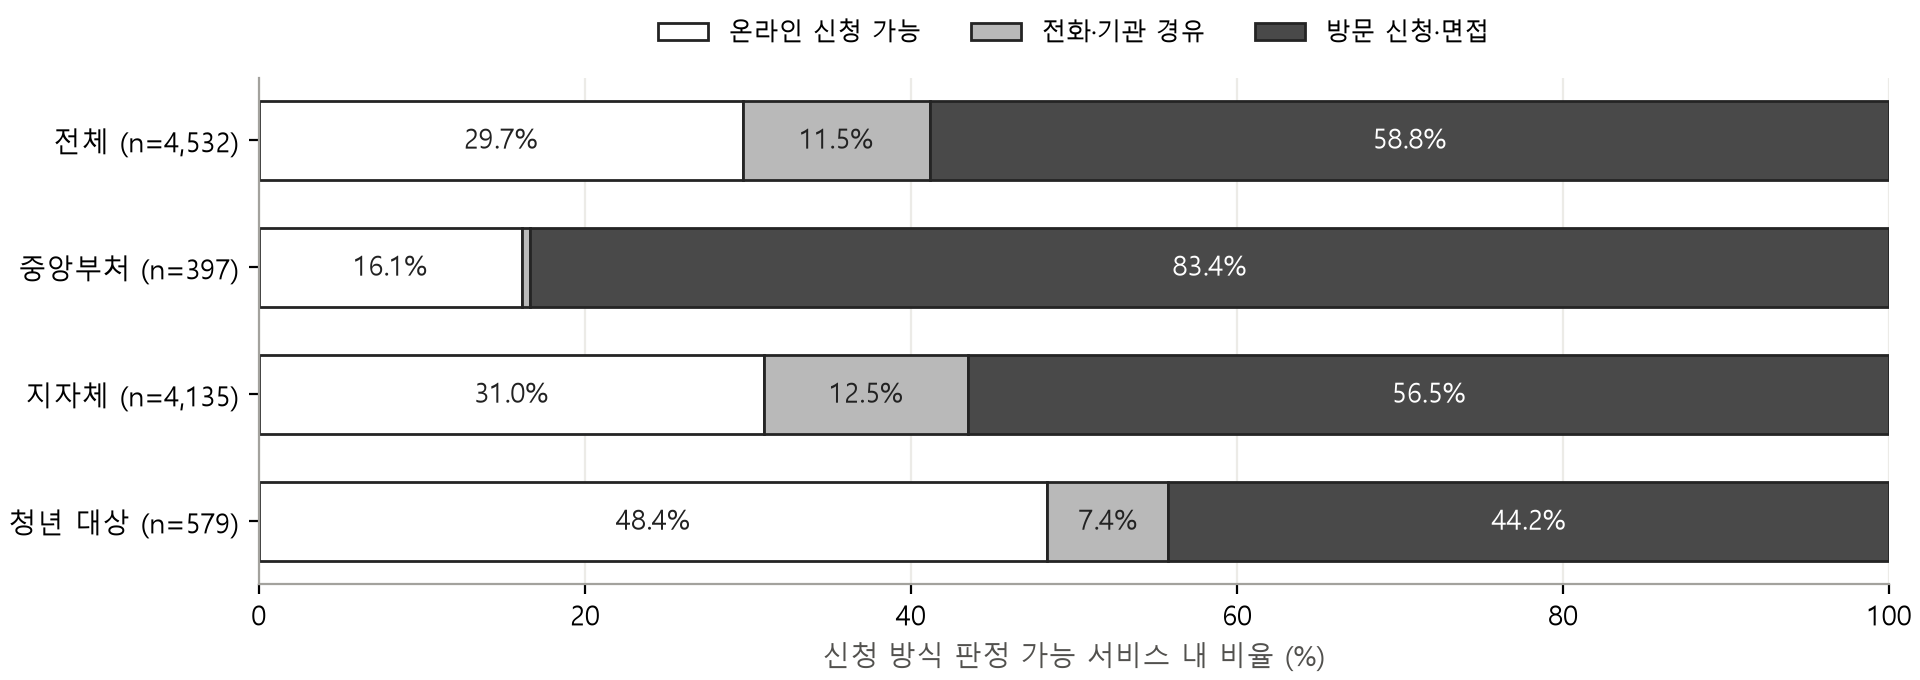

In [5]:
# STEP 01 접근성 분포 그림의 가로 누적 막대 사용
channels = [
    ("온라인", "온라인 신청 가능", "#ffffff", "#222222"),
    ("전화·기관 경유", "전화·기관 경유", "#b9b9b9", "#222222"),
    ("방문·면접", "방문 신청·면접", "#494949", "#ffffff"),
]
fig, ax = plt.subplots(figsize=(9.6, 3.4), layout="constrained")
left = pd.Series(0.0, index=access.index)
for column, label, color, text_color in channels:
    percentages = access[f"{column}(%)"]
    ax.barh(access.index, percentages, left=left, label=label, color=color, edgecolor="#242424", height=0.62)
    for index, (start, share) in enumerate(zip(left, percentages)):
        if share >= 5:
            ax.text(start + share / 2, index, f"{share:.1f}%", color=text_color, ha="center", va="center")
    left += percentages
ax.set_yticks(access.index, [f"{group} (n={n:,})" for group, n in zip(access["집단"], access["신청 판정 가능"])])
ax.set(xlim=(0, 100), xlabel="신청 방식 판정 가능 서비스 내 비율 (%)")
ax.invert_yaxis()
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False)
figure1 = OUTPUT / "figures/application_channels.png"
figure1.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure1, facecolor="white")
plt.close(fig)
display(Image(filename=str(figure1), width=900))

### 관찰과 해석

In [6]:
groups = access.set_index("집단")
total, central, youth = (groups.loc[name] for name in ("전체", "중앙부처", "청년 대상"))
display(Markdown(
    f"- 전체 {total['서비스 수']:,.0f}건 중 신청 방식은 {total['신청 판정 가능']:,.0f}건, 비대면 여부는 "
    f"{total['비대면 판정 가능']:,.0f}건에서 판정함\n"
    f"- 방문·면접 비율은 전체 {total['방문·면접(%)']:.1f}%, 중앙부처 {central['방문·면접(%)']:.1f}%임\n"
    f"- 온라인 신청 분류는 전체 {total['온라인(%)']:.1f}%, 청년 대상 {youth['온라인(%)']:.1f}%임\n"
    f"- 신청·이용 비대면 완결은 전체 {total['비대면 완결']:,.0f}/{total['비대면 판정 가능']:,.0f}건"
    f"({total['비대면 완결(%)']:.1f}%), 청년 대상 {youth['비대면 완결']:,.0f}/{youth['비대면 판정 가능']:,.0f}건"
    f"({youth['비대면 완결(%)']:.1f}%)임\n"
    f"- 고립·은둔 명시는 전체 {total['고립·은둔 명시']:,.0f}건({total['고립·은둔 명시(%)']:.2f}%), "
    f"청년 대상 {youth['고립·은둔 명시']:,.0f}건({youth['고립·은둔 명시(%)']:.2f}%)임"
))

- 전체 5,288건 중 신청 방식은 4,532건, 비대면 여부는 3,727건에서 판정함
- 방문·면접 비율은 전체 58.8%, 중앙부처 83.4%임
- 온라인 신청 분류는 전체 29.7%, 청년 대상 48.4%임
- 신청·이용 비대면 완결은 전체 1,255/3,727건(33.7%), 청년 대상 250/514건(48.6%)임
- 고립·은둔 명시는 전체 19건(0.36%), 청년 대상 6건(0.99%)임

- 유용한 서비스가 ‘저소득 청년’, ‘미취업 청년’, ‘1인 가구’ 등 다른 대상 이름으로 안내될 수 있음
- 온라인 신청 여부만으로 본인 인증·서류 준비의 부담을 모두 알기는 어려움

## Q1. 필요한 지원과 집에서 이용할 수 있는 서비스

- 조사 응답의 ‘매우 필요’ 비율과 해당 지원을 제공하는 서비스 후보 수를 비교함
- 서비스 후보는 청년 특화 사업과 원문 연령 근거가 확인된 일반 사업을 중심으로 선정함
- ‘집 조건 확인’은 원문에서 집에서 신청·이용할 수 있는 것으로 확인된 서비스를 뜻함
- 하나의 서비스가 여러 지원 영역에 포함될 수 있음

### 지원 필요도 계산

$$
\text{지원 필요 비율(\%)} =
\frac{\text{필요하다고 응답한 사람 수}}{\text{해당 문항에 유효하게 응답한 사람 수}}\times 100
$$

- 주 지표는 ‘매우 필요’, 보조 지표는 ‘약간 필요’와 ‘매우 필요’를 합산한 비율임
- 문항별 무응답은 분모에서 제외하고, 각 응답에 같은 비중을 적용함

In [7]:
from src.gap_index import q1_demand as D, q1_final as F, q1_followup as Followup, q1_policy_results as Q1
from src.labeling import q1_human as H

current = load_master()
hiki, iso = D.load_demand()
q1_demand = D.demand_by_group(hiki, iso)
gold, trace, _ = H.build_gold()
reviewed = F.overlay(Followup.revise(current)[0], gold, trace)
q1 = Q1.calculate(q1_demand, reviewed)

reference = q1["final_policy_reference"].dropna(subset=["demand_rank_4"])
q1_table = reference.merge(q1["final_policy_access"][["area", "n_home", "n_not_assessed"]],
                           on="area", validate="one_to_one")
q1_view = q1_table.sort_values("demand_rank_4").assign(
    very_needed_pct=100 * q1_table["rate_very_needed_4"]
)[["area_label", "very_needed_pct", "n_services_final", "n_home", "n_not_assessed"]].rename(columns={
    "area_label": "지원 영역", "very_needed_pct": "매우 필요(%)", "n_services_final": "서비스 후보",
    "n_home": "집 조건 확인", "n_not_assessed": "접근 미검토",
})
save_table(q1_view, "q1_needs_supply.csv")
display(q1_view.round({"매우 필요(%)": 1}).reset_index(drop=True))

top_need = q1_view.iloc[0]
display(Markdown(
    f"- ‘매우 필요’ 비율이 가장 높은 영역은 {top_need['지원 영역']}({top_need['매우 필요(%)']:.1f}%)이며, "
    f"해당 서비스 후보 {top_need['서비스 후보']:,}건 중 집 조건 확인 후보는 {top_need['집 조건 확인']:,}건임"
))

,지원 영역,매우 필요(%),서비스 후보,집 조건 확인,접근 미검토
0,경제적 지원,60.9,51,13,3
1,취업(정보)·일 경험 지원,51.0,203,18,1
2,혼자 하는 취미·문화·체육활동 지원,44.2,46,2,0
3,일상생활 회복 지원,43.5,3,0,0
4,눈치 보지 않고 들러서 머물 수 있는 공간,42.2,2,0,2
5,교육·학습 지원,38.1,48,11,0
6,전문가에 의한 상담·치료,36.7,19,3,0
7,같이 하는 취미·문화·체육활동 지원,24.4,0,0,0
8,공동생활(규칙적인 생활 등),20.4,0,0,0
9,"또래, 멘토 등에 의한 상담·지지",17.3,4,1,0


- ‘매우 필요’ 비율이 가장 높은 영역은 경제적 지원(60.9%)이며, 해당 서비스 후보 51건 중 집 조건 확인 후보는 13건임

- 집 조건 확인 건수는 검토된 원문에서 확인한 후보이며, 개인의 자격·지역 적합성은 별도 요건임
- 영역별 수요 비율과 등록 건수는 단위가 달라 순위와 분포를 나란히 해석함

### 지원 필요도와 집단 차이

- 고립 보조집단은 고립 관련 조사 응답자 중 19~34세를 추린 비교집단임
- 왼쪽은 은둔 표본의 영역별 지원 필요도, 오른쪽은 두 집단의 나이 구성을 같게 맞춘 뒤 비교한 차이임
- 점은 계산한 값, 선은 값의 불확실성을 나타내는 95% 신뢰구간임
- 조사 참여자의 결과이며 전체 청년의 필요도로 일반화하기 어려움

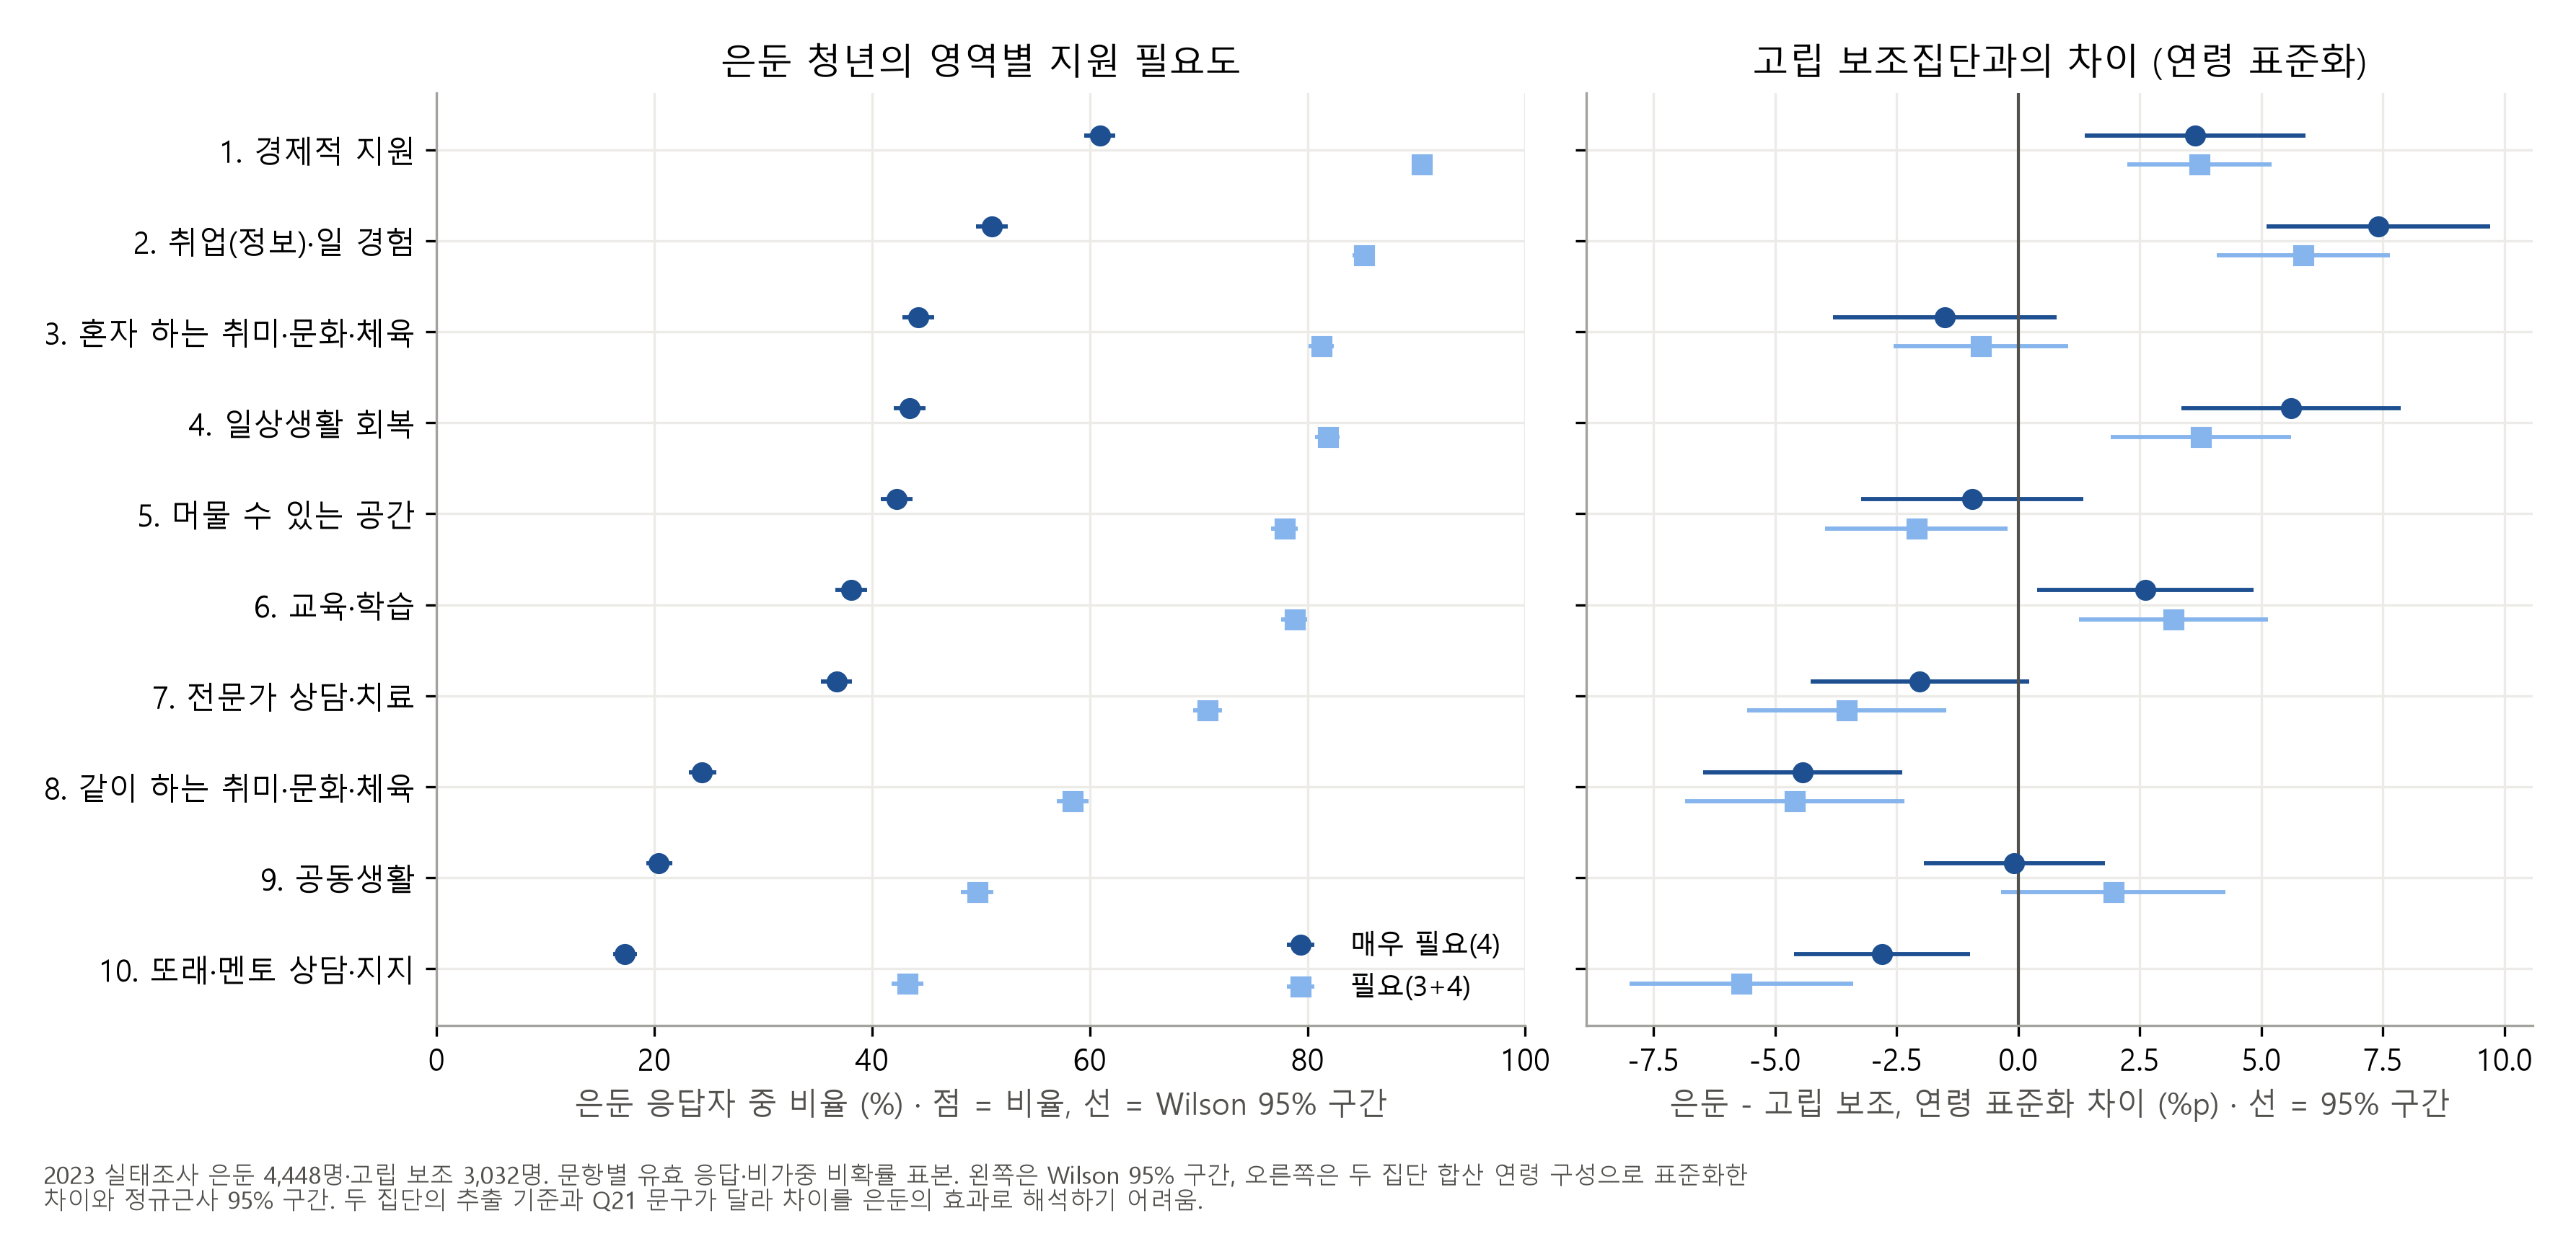

In [8]:
dem = q1_demand
ORDER = dem.query("group == 'hikikomori' and primary_measure").sort_values('rank')['area'].tolist()
std = D.age_standardized_comparison(hiki, iso)
save_table(std, 'q1_age_standardized_comparison.csv')
save_table(dem, 'q1_demand_rates.csv')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.06})
y = np.arange(len(ORDER))[::-1]
for meas, col, mk, off in (("very_needed_4", C_M4, "o", 0.16), ("needed_3_4", C_M34, "s", -0.16)):
    d = dem[(dem["group"] == "hikikomori") & (dem["measure"] == meas)].set_index("area").loc[ORDER]
    a1.errorbar(d["rate"] * 100, y + off, xerr=[(d["rate"] - d["ci95_lo"]) * 100, (d["ci95_hi"] - d["rate"]) * 100], fmt=mk, color=col, ms=6, lw=1.4, label=MEAS_KO[meas])
    s_ = std[(std["standard"] == "pooled") & (std["measure"] == meas)].set_index("area").loc[ORDER]
    a2.errorbar(s_["std_diff_pp"], y + off, xerr=[s_["std_diff_pp"] - s_["std_diff_ci95_lo_pp"], s_["std_diff_ci95_hi_pp"] - s_["std_diff_pp"]], fmt=mk, color=col, ms=6, lw=1.4, label=MEAS_KO[meas])
a2.axvline(0, color=INK2, lw=1)
a1.set_yticks(y, [f"{i + 1}. {SHORT[a]}" for i, a in enumerate(ORDER)])
a1.set_xlabel("은둔 응답자 중 비율 (%) · 점 = 비율, 선 = Wilson 95% 구간"); a2.set_xlabel("은둔 - 고립 보조, 연령 표준화 차이 (%p) · 선 = 95% 구간")
a1.set_title("은둔 청년의 영역별 지원 필요도"); a2.set_title("고립 보조집단과의 차이 (연령 표준화)")
a1.legend(loc="lower right"); a1.set_xlim(0, 100)

save_figure(fig, "q1_support_needs.png",
            f"2023 실태조사 은둔 {len(hiki):,}명·고립 보조 {len(iso):,}명. 문항별 유효 응답·비가중 비확률 표본. "
            "왼쪽은 Wilson 95% 구간, 오른쪽은 두 집단 합산 연령 구성으로 표준화한 차이와 정규근사 95% 구간. "
            "두 집단의 추출 기준과 Q21 문구가 달라 차이를 은둔의 효과로 해석하기 어려움.")

### 필요한 지원과 집에서 시작할 수 있는 후보

- 수요 순서에 맞춰 서비스 후보와 집 조건 확인 건수를 함께 표시함
- 후보 수가 0이거나 적은 영역은 실제 서비스 부재와 분류 누락을 추가 구분할 필요가 있음

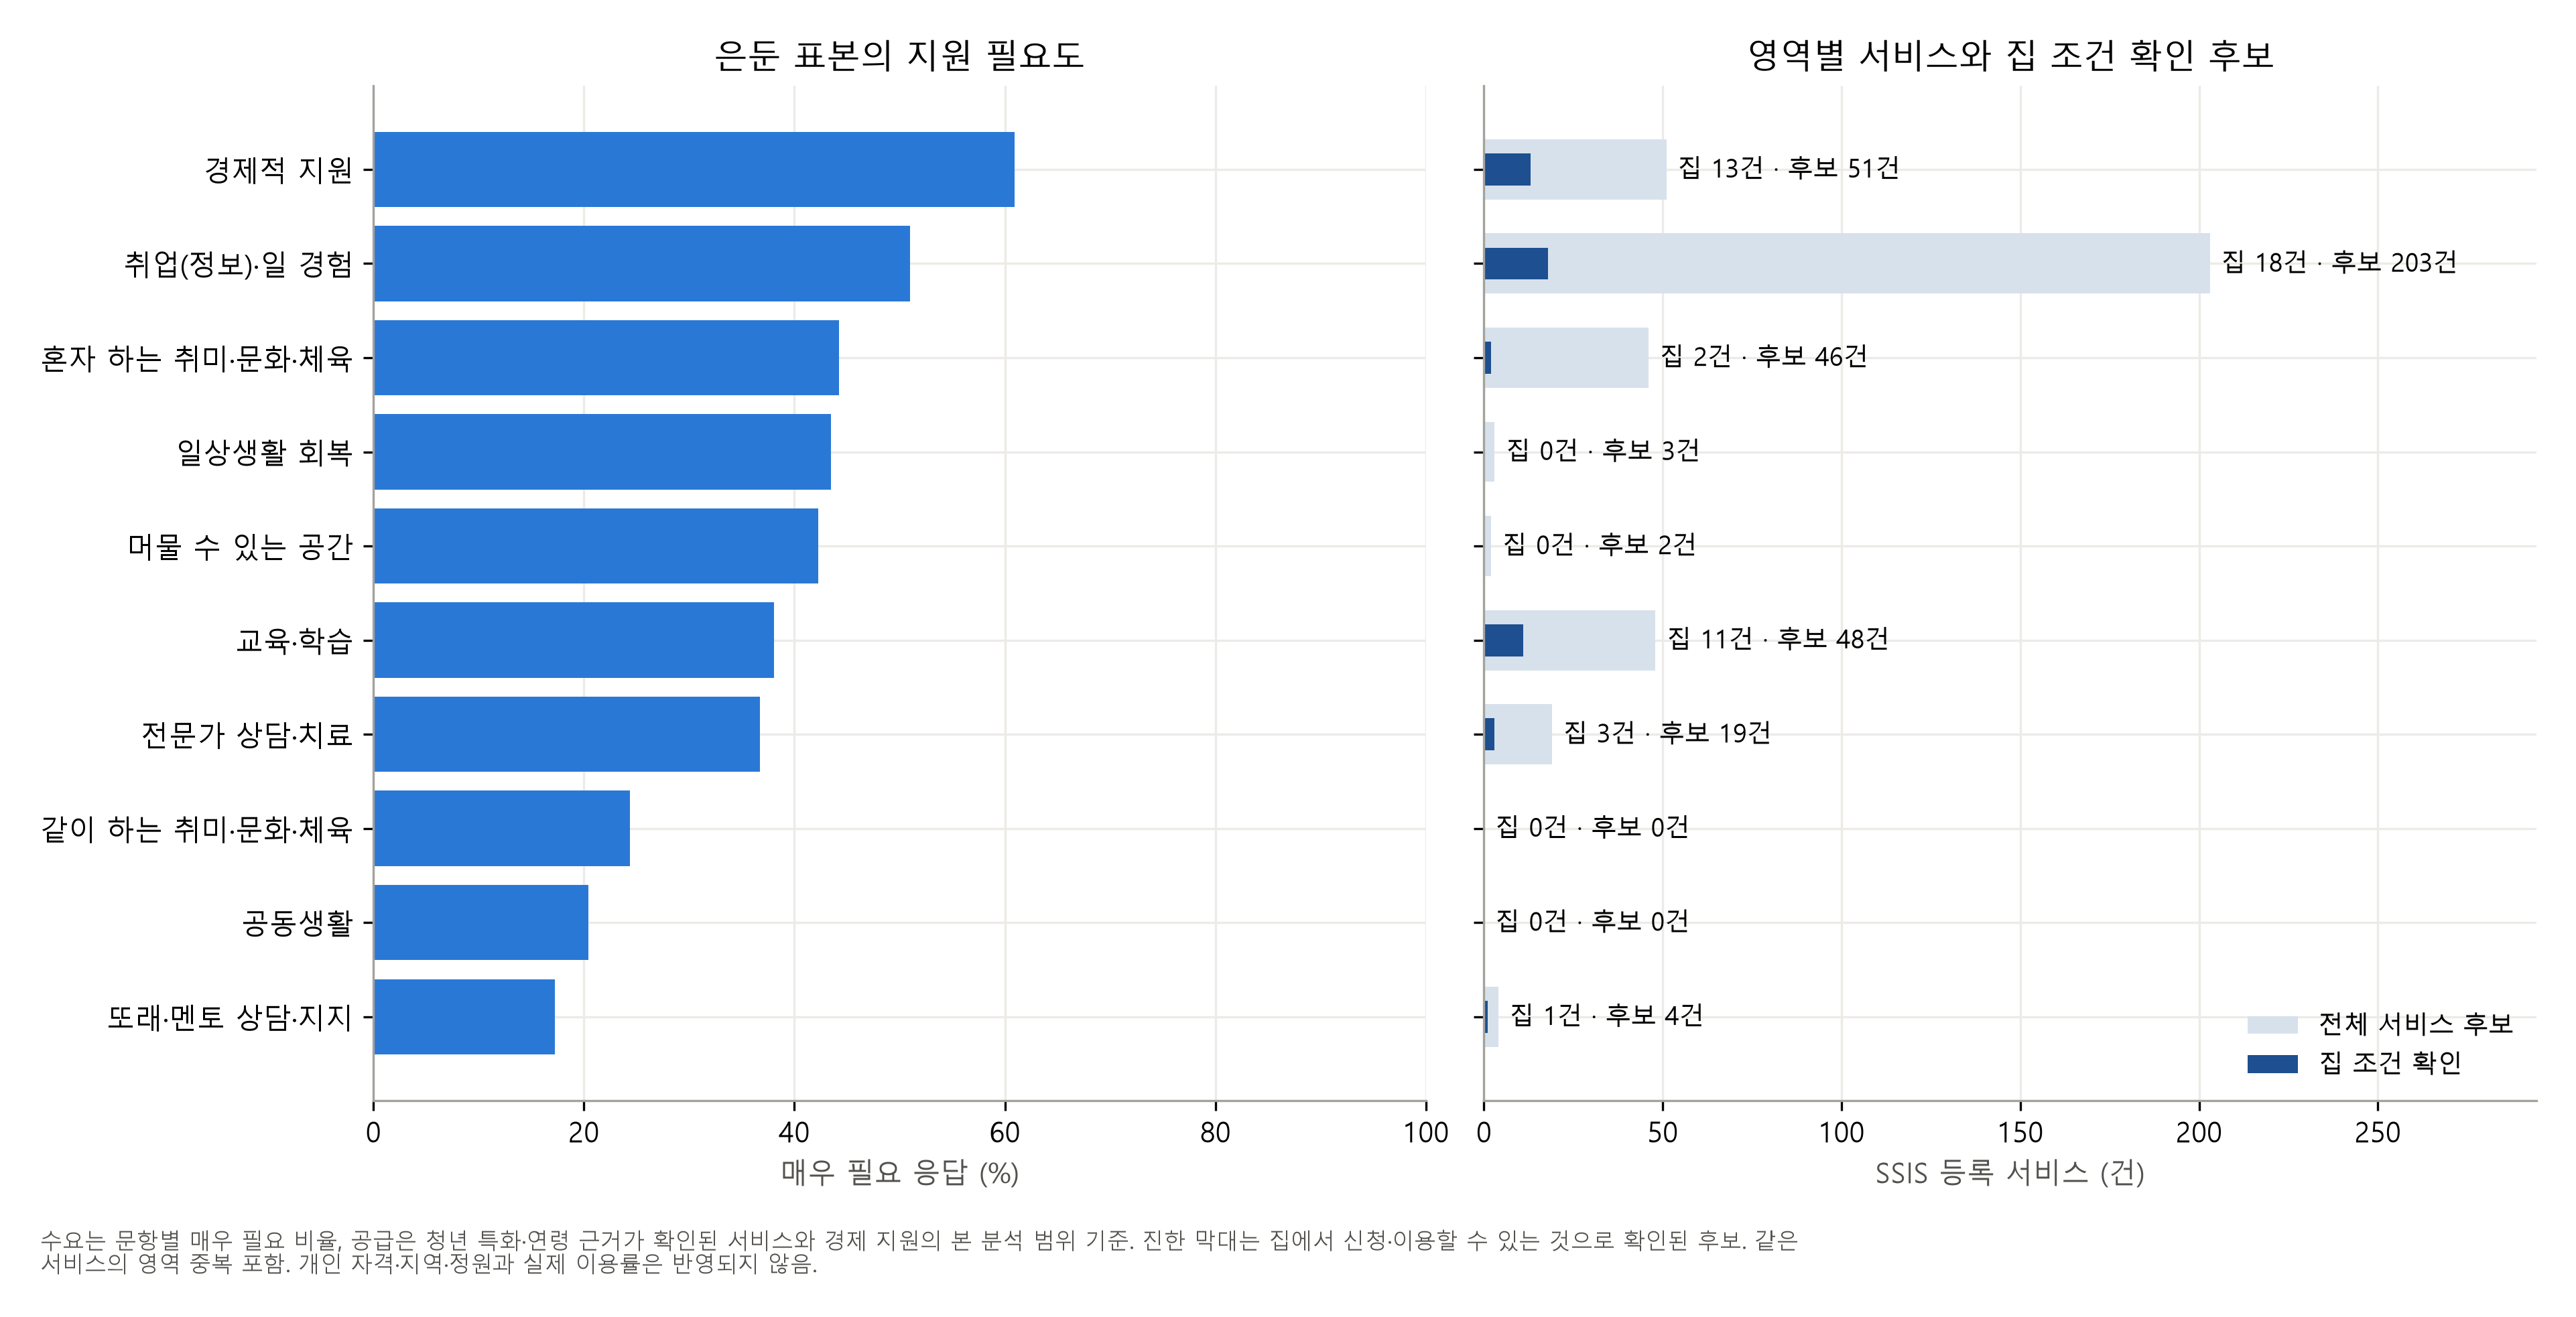

In [9]:
supply_plot = q1_table.sort_values("demand_rank_4").reset_index(drop=True)
positions = np.arange(len(supply_plot))
fig, (left, right) = plt.subplots(1, 2, sharey=True, figsize=(12.5, 5.8), layout="constrained")
left.barh(positions, 100 * supply_plot["rate_very_needed_4"], color=C_HIKI)
left.set_yticks(positions, [SHORT[area] for area in supply_plot["area"]])
left.invert_yaxis()
left.set(title="은둔 표본의 지원 필요도", xlabel="매우 필요 응답 (%)", xlim=(0, 100))

right.barh(positions, supply_plot["n_services_final"], height=.64,
           color="#d7e1eb", label="전체 서비스 후보")
bars = right.barh(positions, supply_plot["n_home"], height=.34,
                  color="#1d4f91", label="집 조건 확인")
for position, row in supply_plot.iterrows():
    right.text(row["n_services_final"] + 3, position,
               f"집 {row['n_home']}건 · 후보 {row['n_services_final']}건", va="center", fontsize=9)
right.set(title="영역별 서비스와 집 조건 확인 후보", xlabel="SSIS 등록 서비스 (건)")
right.set_xlim(0, supply_plot["n_services_final"].max() * 1.45)
right.legend(loc="lower right")
save_figure(fig, "q1_needs_accessible_supply.png",
            "수요는 문항별 매우 필요 비율, 공급은 청년 특화·연령 근거가 확인된 서비스와 경제 지원의 본 분석 범위 기준. "
            "진한 막대는 집에서 신청·이용할 수 있는 것으로 확인된 후보. 같은 서비스의 영역 중복 포함. "
            "개인 자격·지역·정원과 실제 이용률은 반영되지 않음.")

# 4. 복지 연결의 세 가지 격차

## 표 4. 접근 병목과 설계 대응

| 격차 | 이용자가 겪는 문제 | 분석 근거 | 설계 대응 |
|---|---|---|---|
| 정보 인지 | 무엇을 받을 수 있는지 찾기 어려움 | 도움 미경험과 정보 부재(표 1), 고립·은둔 명시 서비스 비중(표 3) | 중앙·지자체 정보를 함께 검색하고 적용 조건 제시 |
| 접근 경로 | 전화·방문·대면이 시작을 어렵게 함 | 방문·면접 분류 비중(표 3·그림 1), 검토한 공공 검색에서 외출 조건 필터 확인 어려움 | 신청·이용 부담을 따로 확인하고 부담이 낮은 경로부터 안내 |
| 언어 | 일상어를 행정 용어와 연결하기 어려움 | 서비스는 정책 대상과 자격 용어로 설명됨 | 일상어를 욕구·조건으로 구조화하고 행정어 사전으로 검색 보완 |

- 정보 탐색에 행정어가 필요하고, 이를 확인하는 상담에도 연락이나 방문이 필요해 세 격차가 서로 강화될 수 있음
- 비대면 이용 후보가 존재하므로 공급 확충과 함께 기존 서비스를 발견하고 시작하는 경로를 살펴볼 필요가 있음

## 표 5. 기존 접근 경로와 「반 걸음」

| 경로 | 입력 | 안내 기준 | 외출 부담 반영 | 고립·은둔 특화 |
|---|---|---|---|---|
| 복지로 맞춤 서비스 찾기 | 조건 선택 | 자격 조건 | 별도 기준 확인 어려움 | 일반 복지 |
| 청년미래센터 | 전화·방문 상담 | 상담사 판단 | 방문 상담 중심 | 특화 |
| 정부 온라인 상담창구·자가진단 | 설문·상담 | 위험도 평가와 연계 | 비대면 진입 | 연계 중심 |
| 반 걸음 | 일상어 서술 | 욕구·자격·외출 부담 | 추천·안내에 반영 | 특화 |

- 청년미래센터 시범사업 참여자의 은둔 점수 12.3% 감소와 삶의 만족도 향상이 보고됨
- 논문 인용 자료에서 전담 센터 4곳과 인력 약 50명, 2024년 8월~2025년 6월 약 1,800명 밀착 관리가 보고됨. 가족돌봄청년을 포함함
- 인용 자료의 2028년까지 24곳 확대 계획과 최대 약 54만 명 추정치는 시점과 대상 범위가 다른 지표임
- 「반 걸음」은 집에서 시작할 수 있는 첫 지원을 찾아주고 필요한 경우 기존 상담기관으로 연결하는 역할임

## Q2. 한 플랫폼의 정보만으로 신청을 준비할 수 있는가

- 한국사회보장정보원과 보조금24에서 같은 사업으로 추정되는 서비스 두 건을 한 쌍으로 비교함
- ‘명시’는 해당 정보가 설명문이나 정보 항목에 구체적으로 적혀 있음을 뜻함
- 비교할 핵심 정보는 연령·소득·신청방법·신청기간·구비서류·문의처의 6가지임
- 자동 비교에서 신뢰도가 높은 두 등급(A·B)의 사업 후보를 분석하고, 실제로 같은 사업인지 사람이 확인한 사례를 별도로 검토함

In [10]:
from src.preprocess import q2_final as Q2Final, q2_completeness as Q2

q2 = Q2.build_all(ROOT, final_tabs=Q2Final.build_all(ROOT))
q2_main = q2["svc_completeness_summary"].query(
    "population == 'AB_nonshared' and scope == 'all' and variant == 'main'"
).copy()
platform = {"ssis": "SSIS", "gov": "보조금24", "union": "두 출처 통합"}
q2_main["플랫폼"] = q2_main["source"].map(platform)
q2_main["핵심 항목 모두 명시(%)"] = 100 * q2_main["share_complete"]
q2_view = q2_main[["플랫폼", "n_pairs", "n_items", "n_complete", "핵심 항목 모두 명시(%)"]].rename(columns={
    "n_pairs": "후보 쌍", "n_items": "핵심 항목 수", "n_complete": "모두 명시한 쌍",
})
save_table(q2_view, "q2_platform_completeness.csv")
display(q2_view.round({"핵심 항목 모두 명시(%)": 1}).reset_index(drop=True))

content = q2["content_verdict_summary"].set_index("item").loc["any"]
display(Markdown(
    f"- 사람 확인 동일사업 {int(content['n_human_same_pairs'])}쌍 중 값이 다른 쌍은 "
    f"{int(content['diff_값 상이'])}쌍임\n"
    f"- 값이 다른 쌍 중 실제 충돌 {int(content['n_실제 충돌'])}쌍이 확인됨"
))

,플랫폼,후보 쌍,핵심 항목 수,모두 명시한 쌍,핵심 항목 모두 명시(%)
0,SSIS,1252,6,24,1.9
1,보조금24,1252,6,156,12.5
2,두 출처 통합,1252,6,241,19.2


- 사람 확인 동일사업 38쌍 중 값이 다른 쌍은 5쌍임
- 값이 다른 쌍 중 실제 충돌 2쌍이 확인됨

- 출처 통합으로 명시된 항목이 늘 수 있으며, 엇갈리는 조건은 공식 기준 확인이 필요함
- 자동 후보의 완성도와 사람이 확정한 동일사업의 충돌은 각각 별도 집단에서 확인함

### 신청 정보의 완성도

$$
\text{정보 완성도(\%)} =
\frac{\text{필요한 정보가 모두 적힌 서비스 쌍 수}}{\text{비교한 서비스 쌍 수}}\times 100
$$

- 필요한 정보 중 ‘해당없음’으로 확인된 항목은 채워야 할 항목에서 제외함
- 통합할 때는 항목별로 두 플랫폼 중 더 구체적으로 적힌 정보를 사용함
- 왼쪽은 평균적으로 확인되는 정보의 개수, 오른쪽은 부족한 정보 개수별 서비스 비율임
- 설명문만 볼 때와 별도로 정리된 정보 항목까지 볼 때의 결과를 함께 비교함

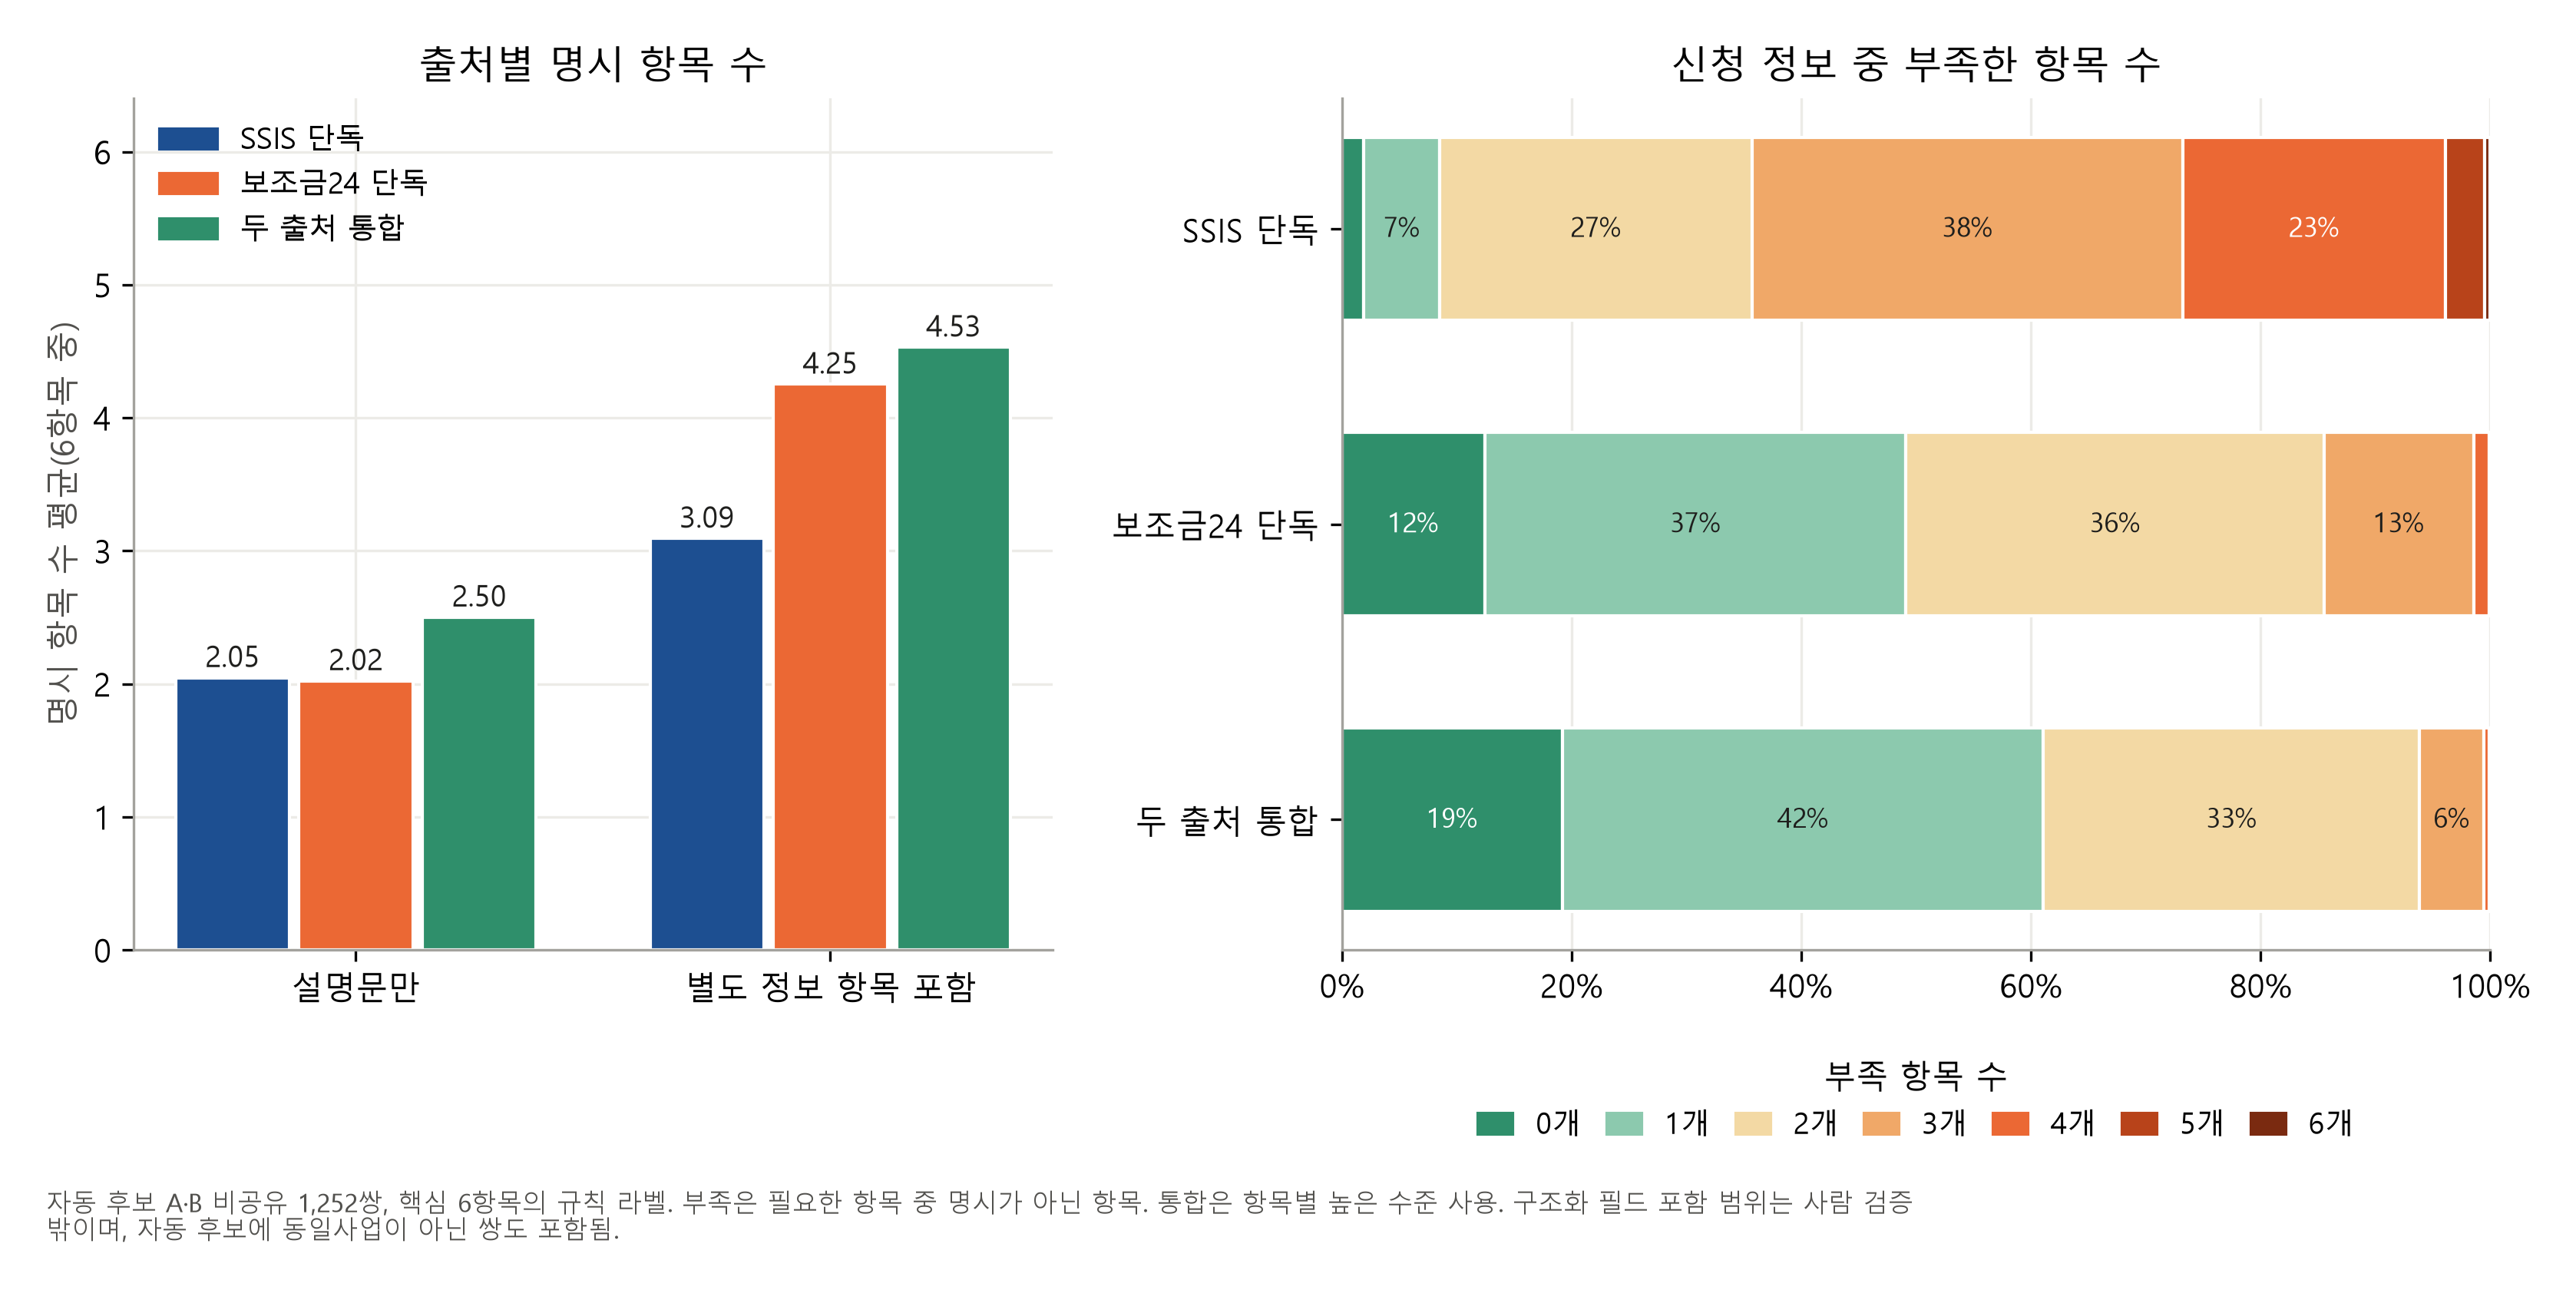

In [11]:
QC, CT = Q2, q2
C_UNION = "#2f8f6b"
SRC_KO = {"ssis": "SSIS 단독", "gov": "보조금24 단독", "union": "두 출처 통합"}
SRC_C = {"ssis": C_DARK, "gov": C_ORANGE, "union": C_UNION}
KO_I = {"age": "연령", "income": "소득", "channel": "신청방법",
        "period": "신청기간", "documents": "구비서류", "contact": "문의처"}
ORDER_I = QC.ITEMS6
POPN = CT["_populations"].set_index("population")["n_pairs"]
SM = CT["svc_completeness_summary"]


def sm_row(population, scope, source):
    return SM.loc[SM["population"].eq(population) & SM["scope"].eq(scope) &
                  SM["source"].eq(source) & SM["variant"].eq("main")].iloc[0]


save_table(SM.query("population == 'AB_nonshared' and variant == 'main'"),
           "q2_completeness_detail.csv")
save_table(CT["svc_short_distribution"].query("population == 'AB_nonshared'"),
           "q2_missing_items_distribution.csv")

dd = CT["svc_short_distribution"]
dd = dd[(dd.population == "AB_nonshared")]
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.28})
ax = axes[0]
for j, scope in enumerate(["text", "all"]):
    for i, s in enumerate(QC.SOURCES):
        r = sm_row("AB_nonshared", scope, s)
        x = j + (i - 1) * 0.26
        ax.bar(x, r.mean_explicit, width=0.24, color=SRC_C[s], edgecolor="white")
        ax.text(x, r.mean_explicit + 0.08, f"{r.mean_explicit:.2f}", ha="center", fontsize=9, color=INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(["설명문만", "별도 정보 항목 포함"])
ax.set_ylim(0, 6.4); ax.set_ylabel("명시 항목 수 평균(6항목 중)"); ax.set_title("출처별 명시 항목 수")
ax.legend(handles=[Patch(color=SRC_C[s], label=SRC_KO[s]) for s in QC.SOURCES], loc="upper left")
ax = axes[1]
SHADE = ["#2f8f6b", "#8cc9ae", "#f3d9a4", "#f0a868", "#eb6834", "#b8431a", "#7a2a10"]
for i, s in enumerate(QC.SOURCES):
    g = dd[(dd.scope == "all") & (dd.source == s)].sort_values("n_short")
    left = 0.0
    for r in g.itertuples():
        ax.barh(i, r.share, left=left, color=SHADE[int(r.n_short)], edgecolor="white", height=0.62)
        if r.share >= 0.05:
            ax.text(left + r.share / 2, i, f"{100 * r.share:.0f}%", ha="center", va="center", fontsize=8.5, color="white" if r.n_short in (0, 4, 5, 6) else INK)
        left += r.share
ax.set_yticks(range(3)); ax.set_yticklabels([SRC_KO[s] for s in QC.SOURCES]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
ax.set_title("신청 정보 중 부족한 항목 수")
ax.legend(handles=[Patch(color=SHADE[k], label=f"{k}개") for k in range(7)], ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.1), title="부족 항목 수", columnspacing=0.9, handlelength=1.2)

save_figure(fig, "q2_service_completeness.png",
            f"자동 후보 A·B 비공유 {int(POPN['AB_nonshared']):,}쌍, 핵심 6항목의 규칙 라벨. "
            "부족은 필요한 항목 중 명시가 아닌 항목. 통합은 항목별 높은 수준 사용. "
            "구조화 필드 포함 범위는 사람 검증 밖이며, 자동 후보에 동일사업이 아닌 쌍도 포함됨.")

### 두 플랫폼은 어떤 정보를 서로 보완하는가

- 회색은 양쪽 모두 정보가 있음, 파랑·주황은 한쪽에만 있음, 연한 회색은 양쪽 모두 구체적인 정보가 부족함을 뜻함
- 두 출처를 합쳐도 남는 빈칸을 통해 추가 확인이 필요한 정보를 살펴봄
- 신청기간의 ‘상시신청’은 기본 입력값일 수 있어 실제 신청기한을 추가 확인할 필요가 있음

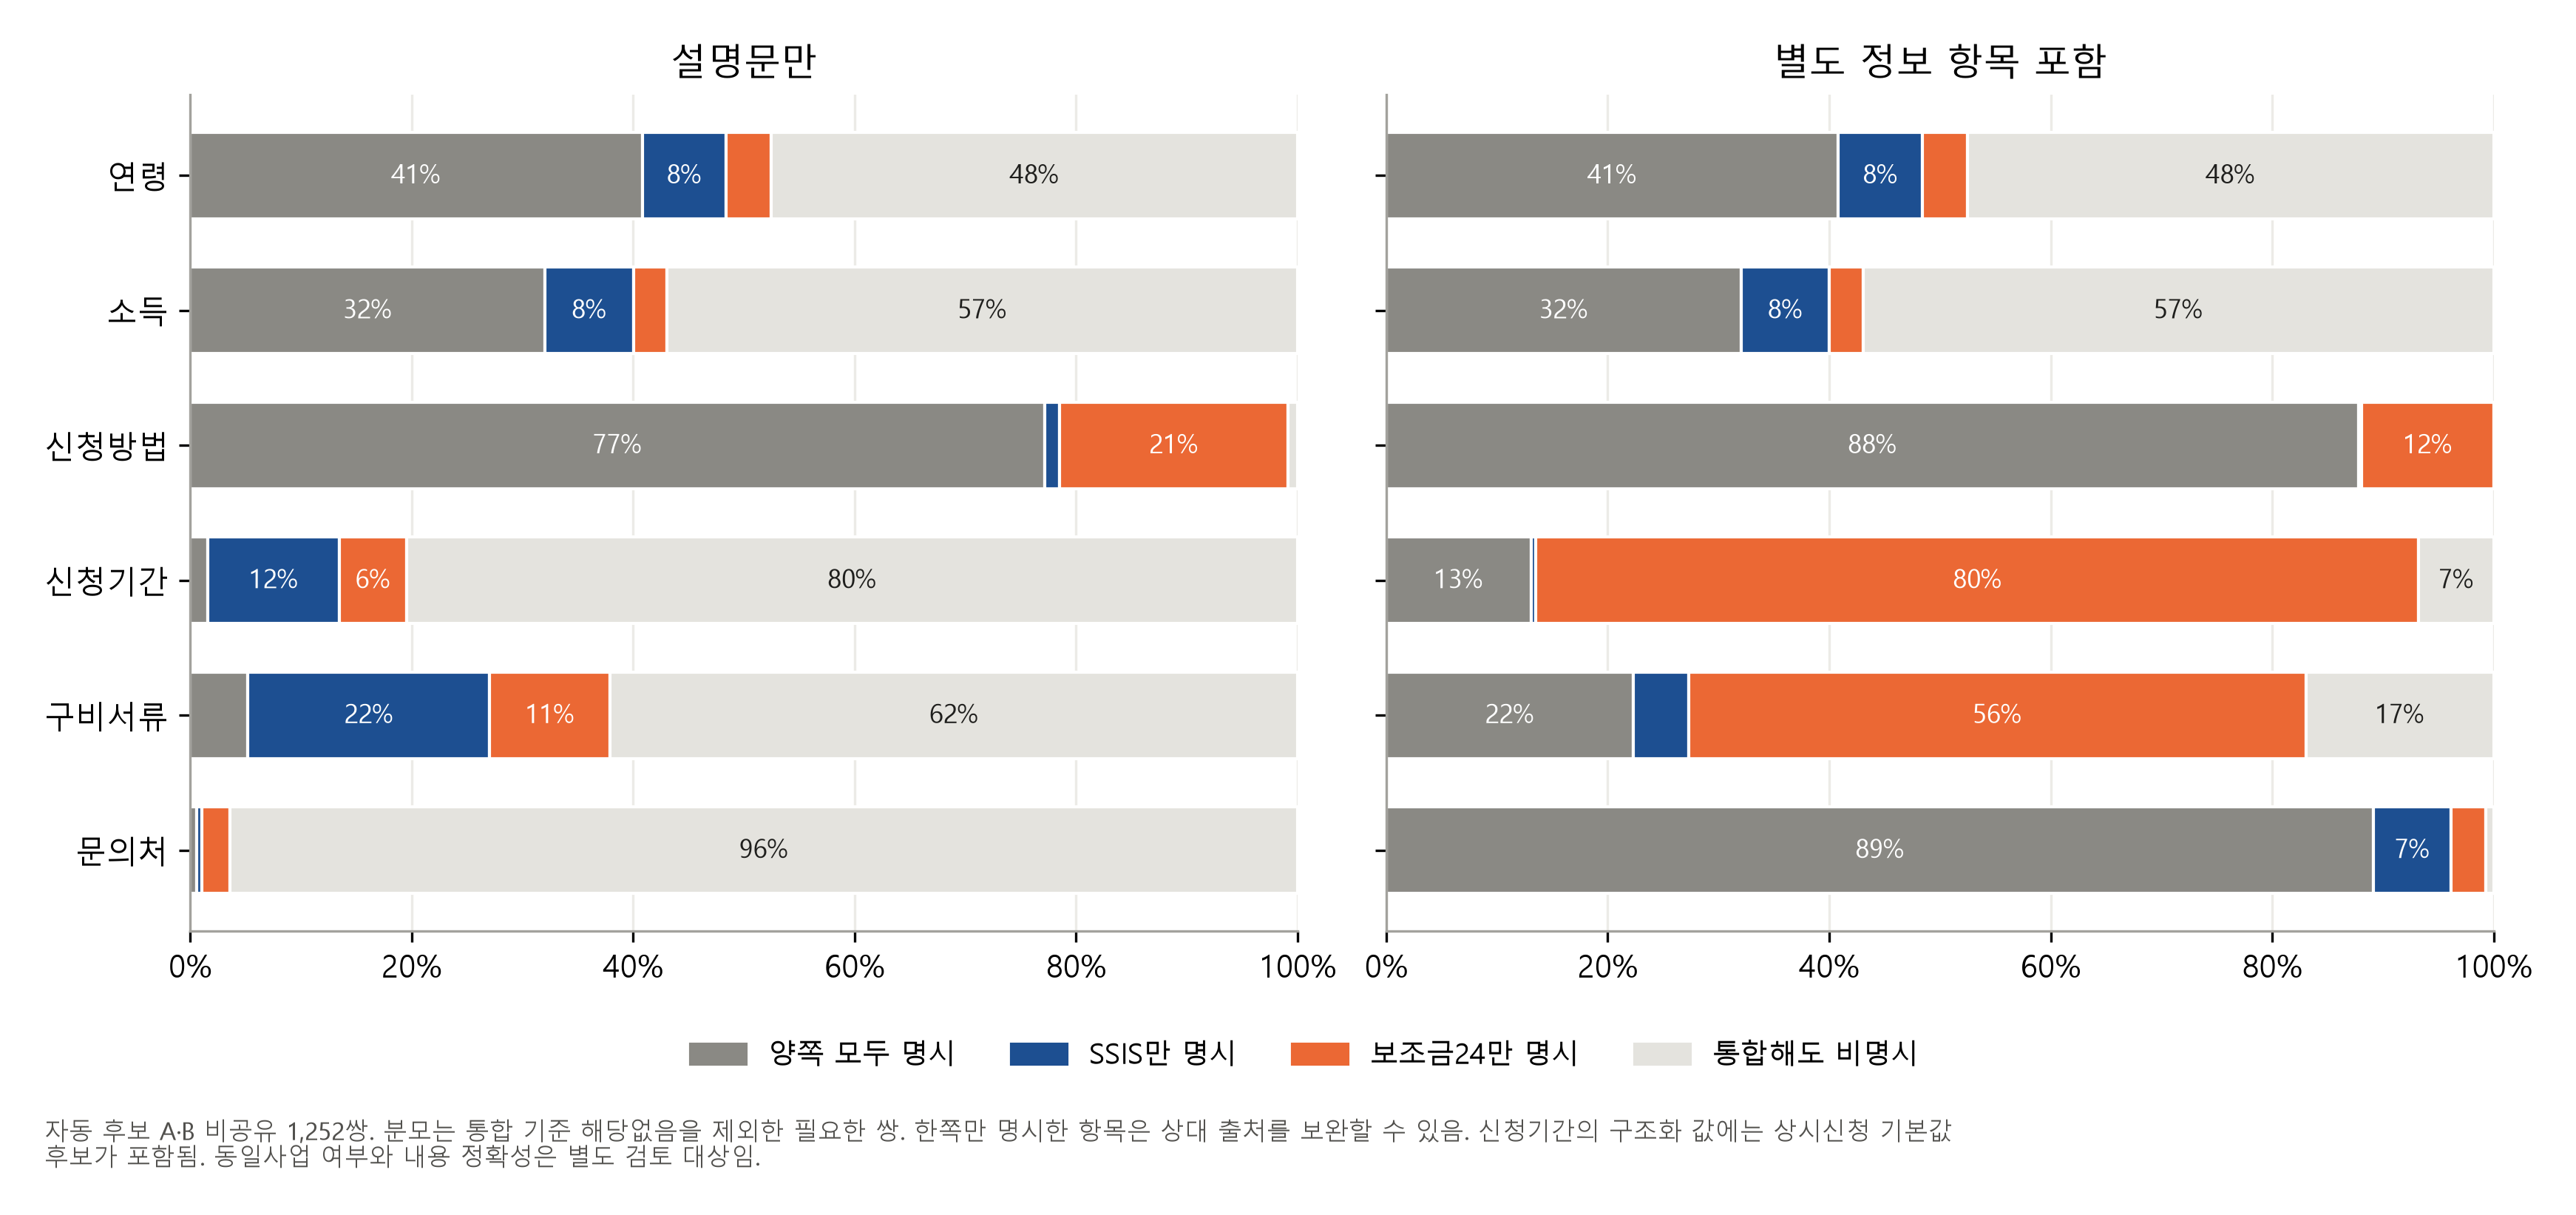

In [12]:
g1 = CT['svc_gain_by_item'].query("population == 'AB_nonshared' and core_metric and variant == 'main'")
save_table(g1, 'q2_integration_by_item.csv')
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.9), sharey=True, gridspec_kw={"wspace": 0.08})
PARTS = [("n_both", "양쪽 모두 명시", "#8a8984"), ("n_ssis_only", "SSIS만 명시", C_DARK), ("n_gov_only", "보조금24만 명시", C_ORANGE), ("n_neither", "통합해도 비명시", "#e4e3de")]
for ax, scope, ttl in zip(axes, ["text", "all"], ["설명문만", "별도 정보 항목 포함"]):
    for k, it in enumerate(ORDER_I):
        r = g1[(g1.scope == scope) & (g1["item"] == it)].iloc[0]
        left = 0.0
        for col, _, color in PARTS:
            v = r[col] / r.n_needed
            ax.barh(k, v, left=left, color=color, edgecolor="white", height=0.64)
            if v >= 0.06:
                ax.text(left + v / 2, k, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8.5, color=INK if col == "n_neither" else "white")
            left += v
    ax.set_yticks(range(6)); ax.set_yticklabels([KO_I[i] for i in ORDER_I]); ax.set_xlim(0, 1); ax.set_title(ttl)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
fig.legend(handles=[Patch(color=c, label=l) for _, l, c in PARTS], ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.04))

save_figure(fig, "q2_integration_by_item.png",
            f"자동 후보 A·B 비공유 {int(POPN['AB_nonshared']):,}쌍. "
            "분모는 통합 기준 해당없음을 제외한 필요한 쌍. 한쪽만 명시한 항목은 상대 출처를 보완할 수 있음. "
            "신청기간의 구조화 값에는 상시신청 기본값 후보가 포함됨. 동일사업 여부와 내용 정확성은 별도 검토 대상임.")

# 5. 비대면 연결 모델 「반 걸음」

## 설계 원칙

- 전화·방문·가입 없이 일상어로 시작하고, 신청과 이용의 외출·대면 부담을 확인함
- 위기 신호가 감지되면 일반 추천을 멈추고 전문기관 안내를 우선함
- 확인된 조건과 추가 확인이 필요한 조건을 규칙으로 구분함
- 추천 이유와 신청방법을 공공 데이터 원문과 함께 제시함

## 그림 2. 「반 걸음」 처리 과정

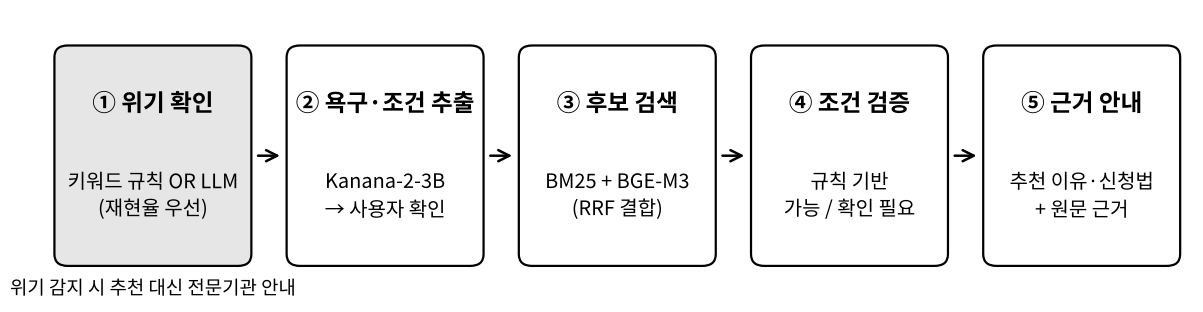

- **위기 확인** — 키워드 규칙과 LLM 판정을 OR로 결합해 둘 중 하나가 감지하면 위기 경로로 전환함. 재현율을 우선함
- **욕구·조건 추출** — Kanana-2-3B-Instruct로 욕구, 활동 범위(방 안·집 안·집 근처·필요하면 외출), 나이·지역을 추출하고 사용자가 확인·수정함
- **후보 검색** — 일상어를 행정어 사전으로 보완하고 BM25의 키워드 순위와 BGE-M3의 의미 순위를 RRF로 결합함. 두 검색의 순위가 높을수록 결합 점수가 커짐
- **조건 검증** — 연령·거주지·외출 조건의 명백한 불일치는 제외하고 자료가 부족한 조건은 ‘확인 필요’로 남김
- **근거 안내** — 추천 이유·신청방법·확인할 조건을 원문과 함께 제공함. 필요하면 당사자가 상황 요약을 상담기관에 전달할 수 있도록 연결함

### 두 검색 결과를 합치는 방식

- BM25는 입력과 서비스 설명에 함께 나오는 단어를 찾아 순위를 매기는 키워드 검색임
- BGE-M3는 표현이 달라도 문장의 의미가 가까운 서비스를 찾는 의미 검색임
- RRF는 두 검색에서 높은 순위에 나온 서비스의 점수를 더하는 결합 방식임

$$
\text{순위 결합 점수}=
\frac{1}{c+\text{키워드 검색 순위}}+
\frac{1}{c+\text{의미 검색 순위}}
$$

- 순위는 1부터 시작하며, 한 검색의 목록에 없는 서비스는 그 검색에서 0점을 받음
- c는 상위 순위에 점수가 지나치게 몰리는 것을 완화하는 보정값임
- 두 검색에 같은 비중을 적용함

## 욕구 영역과 평가 자료

- 여기서 ‘욕구’는 사용자가 필요로 하는 지원을 뜻함
- 청년의 삶 실태조사 영역을 바탕으로 필요한 지원을 9개 영역으로 정리하고 서비스 분류와 연결함
- 일상어 입력 300건의 정답 라벨과 페르소나 카드를 구축하고, 일상어·행정어 대응 쌍을 별도 검수함
- 시나리오 평가 카드와 추출 예시 문장은 분리함
- 표의 ‘—’는 해당 세부 정의 또는 직접 연결되는 조사 문항이 없음을 뜻함. 주거는 별도 서비스 분류로 연결함
- 30억 매개변수의 공개 한국어 모델을 사용해 기관 내부 구동을 고려함. 민감한 입력의 외부 전송을 줄일 수 있는 운영 방식임
- 모델은 추출과 설명에 쓰고 자격 판단은 서비스 원문에 근거한 규칙으로 처리함

In [13]:
domains = pd.DataFrame([
    {
        "욕구 영역": domain,
        "연결되는 핵심 서비스 태그": ", ".join(
            Q21_LABELS[area] for area, app_domain, level, _, _ in APP_DOMAIN_MAP_V3
            if app_domain == domain and level == "핵심"
        ) or "—",
        "세부 기준": APP_DOMAIN_DEFS_V3.get(domain, "—"),
    }
    for domain in APP_DOMAINS_V3
])
display(domains)

,욕구 영역,연결되는 핵심 서비스 태그,세부 기준
0,주거,주거 (Q21에 대응 없음),—
1,건강,전문가에 의한 상담·치료,—
2,일상·여가,"일상생활 회복 지원, 혼자 하는 취미·문화·체육활동 지원, 공동생활(규칙적인 생활 등)","생활 리듬 회복, 혼자 하는 취미·문화·운동 (주 추천 대상은 작은 활동)"
3,관계참여,"눈치 보지 않고 들러서 머물 수 있는 공간, 같이 하는 취미·문화·체육활동 지원, ...",—
4,교육훈련,교육·학습 지원,—
5,미취업(구직),취업(정보)·일 경험 지원,일자리 찾기·일경험·구직
6,노동(일하는 중),—,일하는 중의 근로조건·임금·권익
7,미래설계,—,—
8,경제,경제적 지원,—


## 입력에서 안내까지의 동작 예시

- 가상 입력으로 위기 시 검색 중단, 사용자 확인, 검색·조건 검증, 원문 안내가 이어지는지 확인함
- 이 예시는 동작 확인용 모의 모델을 사용하며, 실제 모델의 검색 성능은 다음 절의 평가 결과에서 확인함

In [14]:
# 프로젝트의 운영 코드 경로 사용. 모의 모드는 GPU·API 키·외부 호출 없이 실행 가능
sys.path.insert(0, str(ROOT / "ai"))
from pipeline import Pipeline

demo = Pipeline(mock=True, services_path=ROOT / MASTER_PATH, as_of="2026-11-14")

crisis_session = demo.prepare("요즘 자살 생각이 자주 들어요.")
crisis_result = demo.search(crisis_session)
assert crisis_result["status"] == "crisis_stop" and not crisis_result["searched"]

user_input = "월세 지원을 찾고 있어요. 밖에 나가는 게 부담스러워요."
prepared = demo.prepare(user_input, profile={"age": 26, "region_sido": "서울"})
assert prepared["status"] == "awaiting_confirm"
confirmed = demo.resume(prepared, {"type": "finish_confirm"})
result = demo.search(confirmed, explain_mode="source_first")
assert confirmed["status"] == "ready" and result["searched"]

stages = pd.DataFrame([
    ("위기 신호 감지", "전문기관 안내" if crisis_result.get("guidance") else "중단", "검색 중단"),
    ("일반 입력", "사용자 확인 후 검색", f"카드 {len(result['cards'])}건"),
], columns=["가상 입력", "처리 흐름", "결과"])
display(stages)

demo_cards = pd.DataFrame([
    {"서비스": card["servNm"], "원문 근거": card["evidence"],
     "신청 경로": card["how_to_apply"], "확인할 조건": ", ".join(card["check_needed"])}
    for card in result["cards"][:2]
])
if not demo_cards.empty:
    display(demo_cards)

,가상 입력,처리 흐름,결과
0,위기 신호 감지,전문기관 안내,검색 중단
1,일반 입력,사용자 확인 후 검색,카드 4건


,서비스,원문 근거,신청 경로,확인할 조건
0,주거안정 월세대출 보증,보증금 1억원 이하 및 월세 60만원 이하인 월세계약을 체결한 주택도시기금 주거안정...,"거주지 읍/면/동 주민센터, 위탁금융기관에서 ‘서비스 신청’","연령, 기간, 접근, 소득"
1,저소득주민 생활안정 지원사업,"전기, 수도, 도시가스 체납으로 단전, 단수, 단가스 위기에 처한 경우건강보험료 체...","해당 읍,면,동주민센터에서 신청","연령, 지역, 기간, 접근, 소득"


# 6. 평가 계획과 확인 범위

## 표 6. 단계별 평가

| 단계 | 지표 | 평가 자료 | 우선 기준 |
|---|---|---|---|
| 서비스 라벨링 | 정확도, 평가자 간 일치도(Cohen의 κ) | 팀원 교차 검수 정답셋 | 라벨 신뢰성 |
| 위기 확인 | 재현율 | 위기 표현을 포함한 입력 | 위기 누락 최소화 |
| 욕구·조건 추출 | 영역·조건 정확도 | 입력 300건과 정답 라벨 | 사용자 수정 전 정확도 |
| 후보 검색 | Recall@5 | 입력별 적합 서비스 정답셋 | 상위 5건에서 적합 서비스 포착 |
| 전체 흐름 | 사용성, 이해도 | 페르소나 시나리오와 사용자 시연 | 추가 연락 없이 신청 경로 이해 |

## Q3. 같은 상황을 일상어로 적어도 서비스를 찾는가

- 같은 필요를 일상어와 행정 용어로 표현한 질의쌍을 검색해 상위 목록이 얼마나 겹치는지 확인함
- 예를 들어 ‘월세가 부담돼요’와 ‘청년 주거비 지원’은 표현이 다른 입력의 예시임
- 별도의 가상 상황 카드에서 각 검색 방식의 추천을 사람이 읽고 직접 도움이 되는 서비스인지 판정함

In [15]:
from src.recommend import q3_run as Q3Baseline, q3_search as Search

q3_queries = Q3Baseline.load_queries()
keyword_index = Search.KeywordIndex(Search.load_master(Q3Baseline.MASTER))
conditions = Search.PRIMARY_CONDITIONS
keyword_ranks, keyword_stats, ranked = Q3Baseline.run_search(keyword_index, q3_queries, conditions)
overlap = Q3Baseline.pair_overlap(q3_queries, ranked, conditions)
q3_baseline = overlap.groupby("cond_id", sort=False).agg(
    질의쌍=("pair_id", "size"),
    평균_공통_서비스=("n_common", "mean"),
    공통_서비스_없는_쌍=("n_common", lambda size: size.eq(0).sum()),
).reset_index().rename(columns={
    "cond_id": "검색 조건", "평균_공통_서비스": "평균 공통 서비스", "공통_서비스_없는_쌍": "공통 서비스 없는 쌍",
})
save_table(q3_baseline, "q3_keyword_overlap.csv")
display(q3_baseline.replace({"검색 조건": {"short_t0_or": "서비스명·요약·대상", "full_t0_or": "상세 설명까지 포함"}}).round({"평균 공통 서비스": 2}))

,검색 조건,질의쌍,평균 공통 서비스,공통 서비스 없는 쌍
0,서비스명·요약·대상,30,0.87,21
1,상세 설명까지 포함,30,0.87,18


### 표현에 따른 검색 결과의 차이

- 점 하나는 같은 필요를 두 표현으로 검색한 질의쌍임
- 세로축은 두 검색의 상위 10개 목록에 공통으로 들어온 서비스 수임
- 공통 서비스가 적을수록 같은 필요도 표현에 따라 다른 결과가 나타남

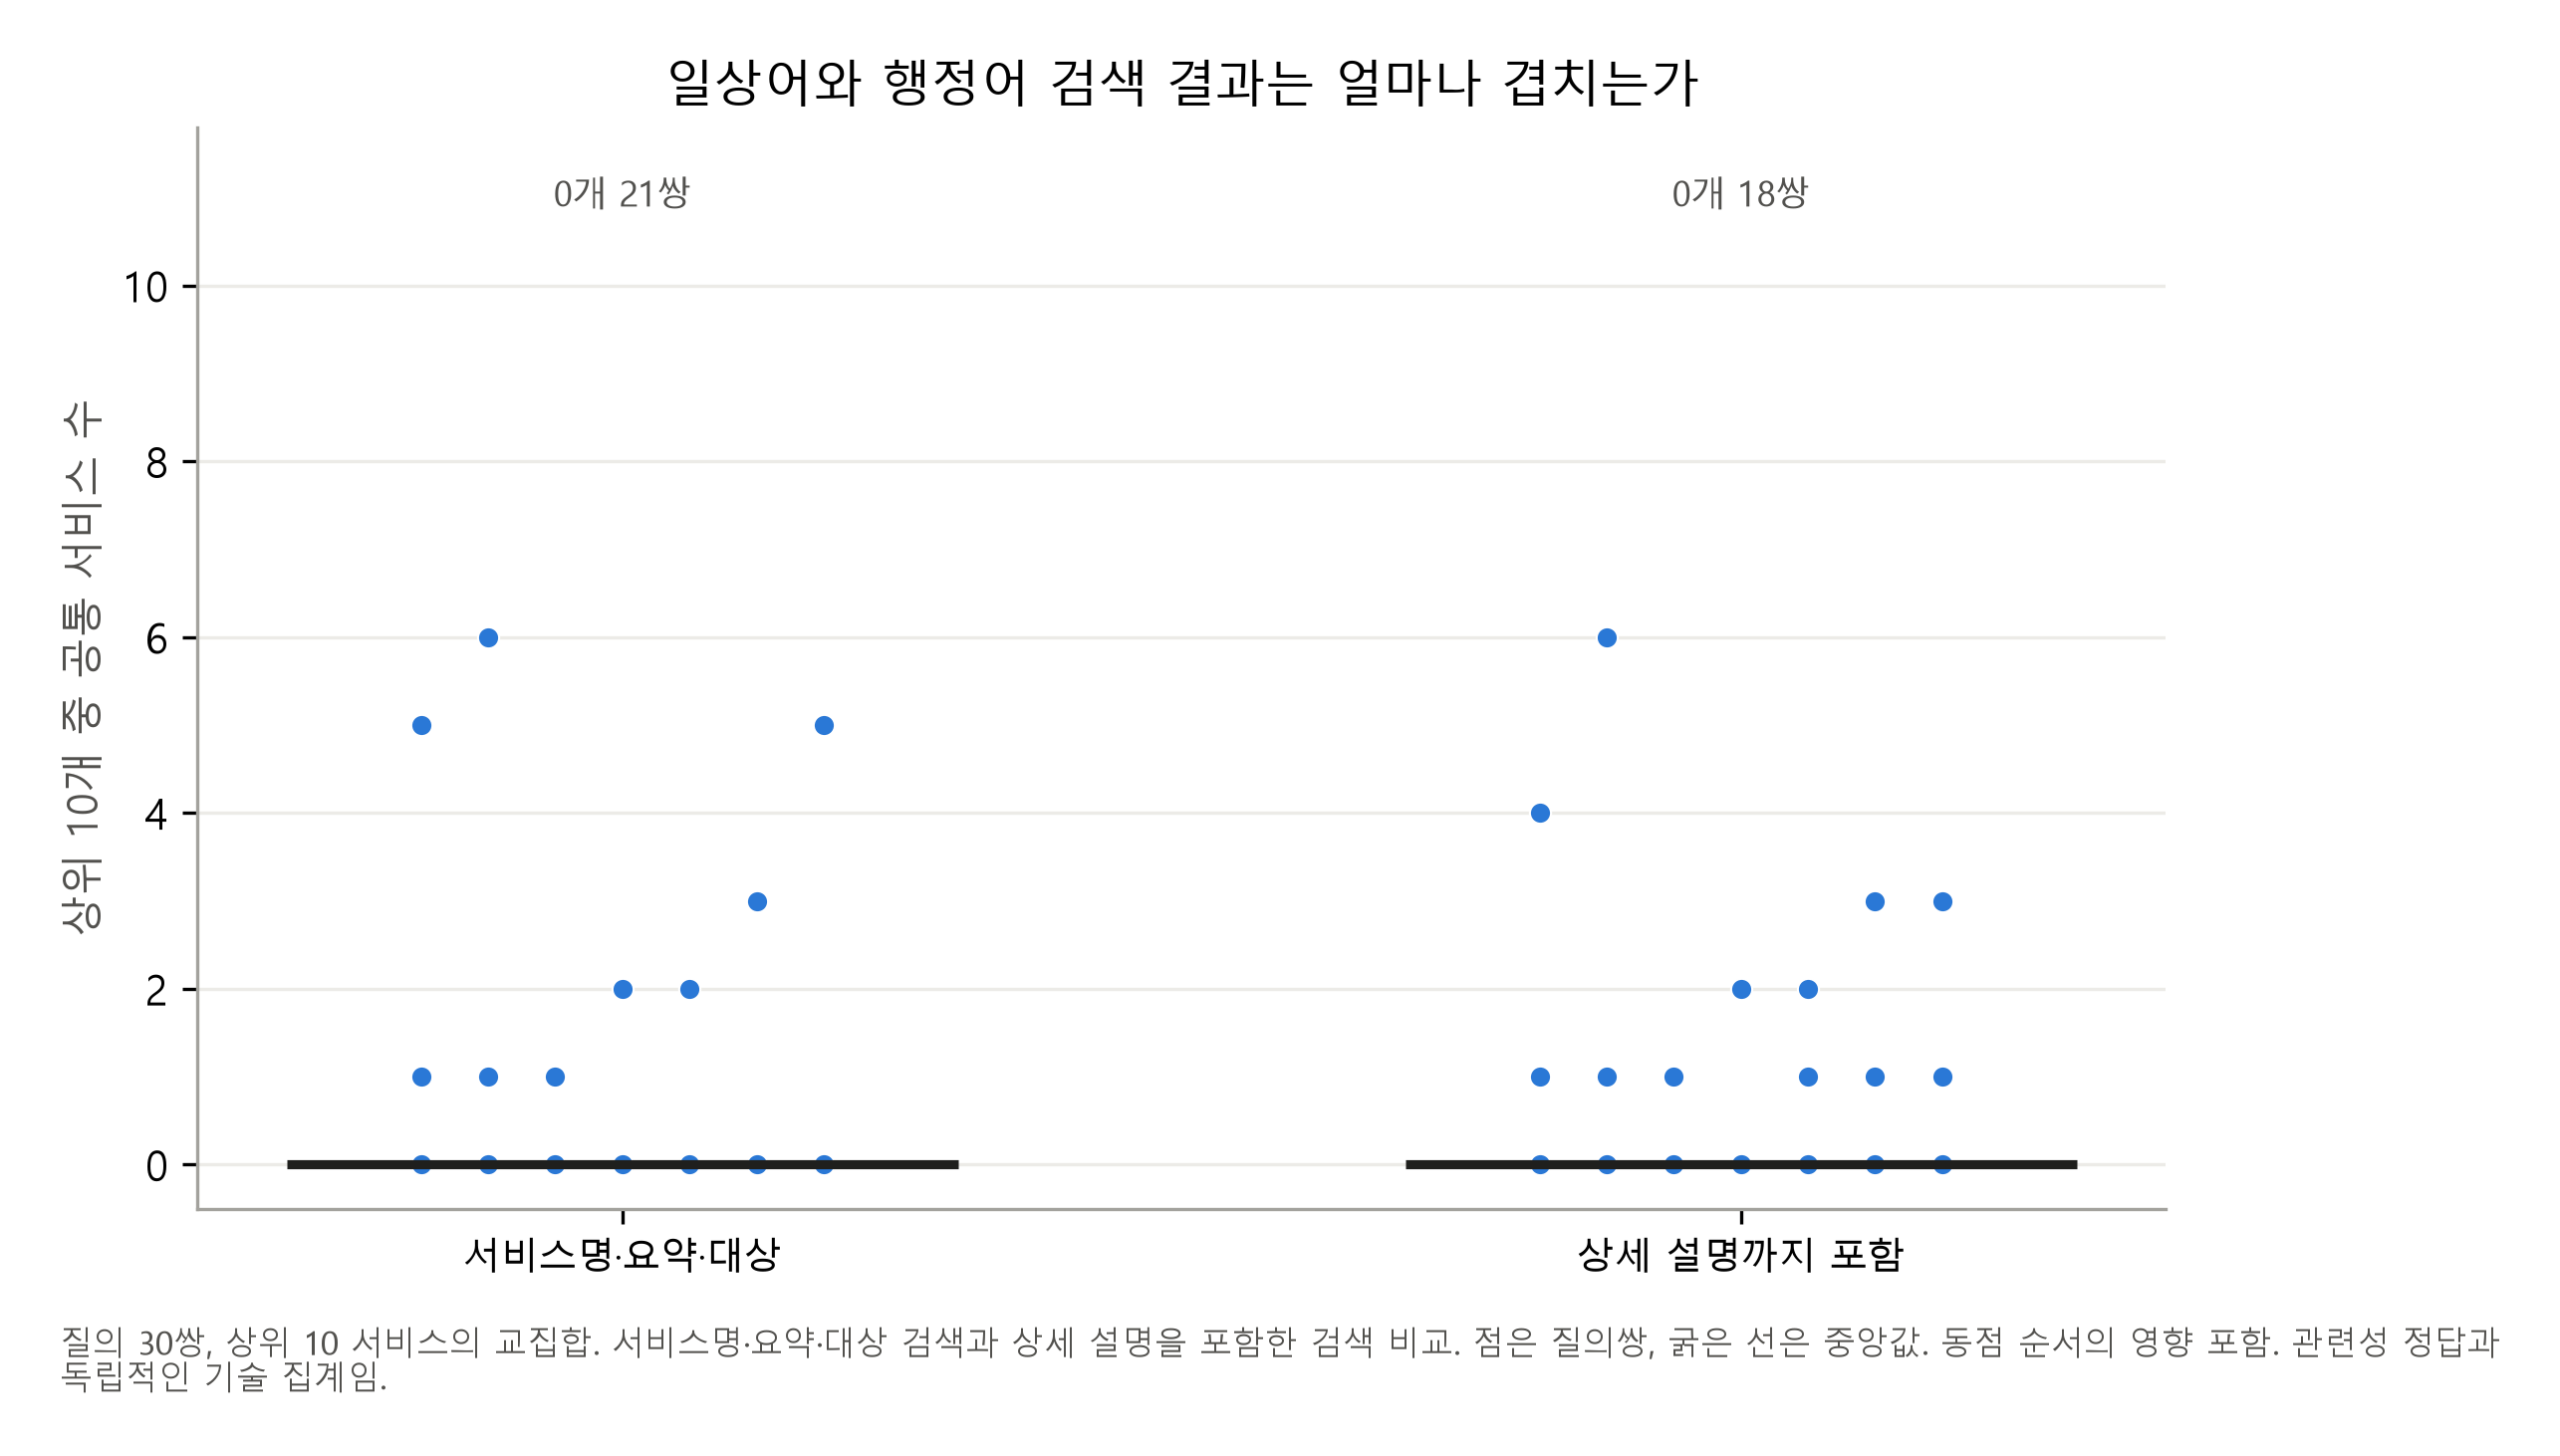

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.7))
for i, cid in enumerate(list(q3_baseline["검색 조건"])):
    s = overlap[overlap.cond_id == cid]["n_common"].to_numpy()
    srt = np.sort(s)
    offs = ((np.arange(len(srt)) % 7) - 3) * 0.06
    main = cid in ("short_t0_or", "full_t0_or")
    ax.scatter(np.full(len(srt), i) + offs, srt, s=26, color=C_MID if main else C_GRAY, edgecolor="white", linewidth=0.5, zorder=2)
    ax.hlines(np.median(s), i - 0.3, i + 0.3, color=INK, lw=2.2, zorder=3)
    ax.text(i, 10.9, f"0개 {int((s == 0).sum())}쌍", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(range(len(list(q3_baseline["검색 조건"]))), ["서비스명·요약·대상", "상세 설명까지 포함"], fontsize=9)
ax.set_ylim(-0.5, 11.8); ax.set_yticks(range(0, 11, 2)); ax.set_ylabel("상위 10개 중 공통 서비스 수"); ax.grid(axis="x", visible=False)
ax.set_title("일상어와 행정어 검색 결과는 얼마나 겹치는가")

save_table(overlap, "q3_keyword_overlap_by_pair.csv")
save_figure(fig, "q3_top10_overlap.png",
            f"질의 {q3_queries['pair_id'].nunique()}쌍, 상위 10 서비스의 교집합. "
            "서비스명·요약·대상 검색과 상세 설명을 포함한 검색 비교. "
            "점은 질의쌍, 굵은 선은 중앙값. 동점 순서의 영향 포함. 관련성 정답과 독립적인 기술 집계임.")

- 겹침 지표는 같은 의도를 서로 다르게 표현했을 때 후보 목록이 달라지는 정도임
- 관련성은 사람 판정으로 확인함. Precision@5의 분모는 추천 슬롯, Recall@5의 분모는 관련 서비스 정답임
- 전체 DB의 관련성 정답을 확보하지 못해 재현율은 검수 후보군 안에서만 해석함

### 검색 성능을 읽는 방법

$$
\mathrm{Precision@5}=
\frac{\text{상위 5개 중 요청에 직접 도움이 되는 서비스 수}}{5}
$$

$$
\mathrm{Success@5}=
\frac{\text{도움이 되는 서비스를 1개 이상 찾은 입력 수}}{\text{평가한 입력 수}}
$$

| 지표 | 의미 |
|---|---|
| Precision@5 | 추천 5개 중 요청에 직접 도움이 되는 서비스의 비율 |
| Success@5 | 관련 서비스를 한 개 이상 찾은 입력의 비율 |
| nDCG@5 | 관련 서비스가 추천 목록의 상단에 배치된 정도 |
| 검수 후보군 Recall@5 | 사람이 확인한 관련 서비스 중 상위 5개에서 찾은 비율 |

- 지표는 0~1 범위이며 높을수록 해당 기준의 성능이 좋음을 뜻함
- nDCG와 후보군 내 재현율은 사람이 관련 서비스를 확인한 카드만 분모에 포함함
- 전체 서비스의 관련성을 모두 판정하지 못해 재현율은 사람이 검토한 후보 안에서 해석함
- 아래는 저장된 순위와 사람 판정으로 계산한 평가 시점의 결과임
- 현재 모델은 정보 추출·검색어 생성·추천 성능을 계속 개선 중임

In [17]:
from ai.eval import independent_retrieval as Q3

run = ROOT / "private/q3_run_v1"
rank_file = run / "restricted/rankings.json"
review_folder = run / "review/split_core"
subset_file = review_folder / "subset_with_q1off.json"
if rank_file.is_file() and subset_file.is_file():
    bundle = json.loads(rank_file.read_text(encoding="utf-8-sig"))
    subset = json.loads(subset_file.read_text(encoding="utf-8-sig"))
    reviews = [Q3.independent.read_csv(path) for path in sorted(review_folder.glob("relevance_*.csv"))]
    if not reviews:
        raise FileNotFoundError("Q3 사람 관련성 판정 파일이 필요합니다.")
    combined = pd.concat(reviews, ignore_index=True)
    human = combined.loc[combined["judge_type"].eq("human") &
                         combined["assignment"].isin(["primary", "adjudicated"])]
    scores = Q3.score(bundle, human, subset=subset)

    arm_names = {"bm25": "BM25", "rrf": "BM25 + BGE-M3 (RRF)",
                 "rules_q1off": "규칙 적용", "recommendation": "규칙 + Q1 가점"}
    summary = scores.groupby("arm", sort=False).agg(
        cards=("card_id", "size"),
        precision=("precision_at_k", "mean"),
        ndcg=("ndcg_at_k", "mean"),
        success=("success_at_k", "mean"),
        pool_recall=("pooled_recall_at_k", "mean"),
    ).reset_index()
    summary["arm"] = summary["arm"].map(arm_names)
    summary = summary.rename(columns={
        "arm": "검색 방식", "cards": "평가 카드", "precision": "Precision@5", "ndcg": "nDCG@5",
        "success": "Success@5", "pool_recall": "검수 후보군 Recall@5",
    })
    save_table(summary, "q3_human_scores.csv")
    display(Markdown(f"- 검색 평가 기준일 {bundle['as_of']}"))
    display(summary.round(3))

    paired = Q3.paired_arms(scores, measures=("precision_at_k",))
    interval = paired.loc[paired["arm_a"].eq("bm25") & paired["arm_b"].eq("rrf")].iloc[0]
    display(Markdown(
        f"- RRF의 Precision@5는 BM25보다 {interval['mean_diff']:+.3f} 높음 "
        f"(95% CI {interval['ci95_lo']:+.3f}~{interval['ci95_hi']:+.3f})"
    ))
else:
    display(Markdown("- Q3 사람 판정 재채점에는 비공개 평가 묶음이 필요함"))

- 검색 평가 기준일 2026-11-14

,검색 방식,평가 카드,Precision@5,nDCG@5,Success@5,검수 후보군 Recall@5
0,BM25,32,0.088,0.192,0.344,0.265
1,BM25 + BGE-M3 (RRF),32,0.212,0.480,0.625,0.607
2,규칙 적용,32,0.231,0.510,0.656,0.700
3,규칙 + Q1 가점,32,0.231,0.527,0.656,0.700


- RRF의 Precision@5는 BM25보다 +0.125 높음 (95% CI +0.056~+0.200)

### 어떤 단계에서 검색 성능이 달라졌는가

- 왼쪽은 검색 방식별 Precision@5, 오른쪽은 앞 단계 대비 차이와 95% 신뢰구간임
- 신뢰구간이 0을 포함하면 이 표본에서 추가 개선이 뚜렷한지 판단하기 어려움
- ‘규칙 적용’은 자격·이용 조건 확인, ‘Q1 가점’은 필요한 지원에 맞는 서비스를 먼저 보여주기 위한 점수임

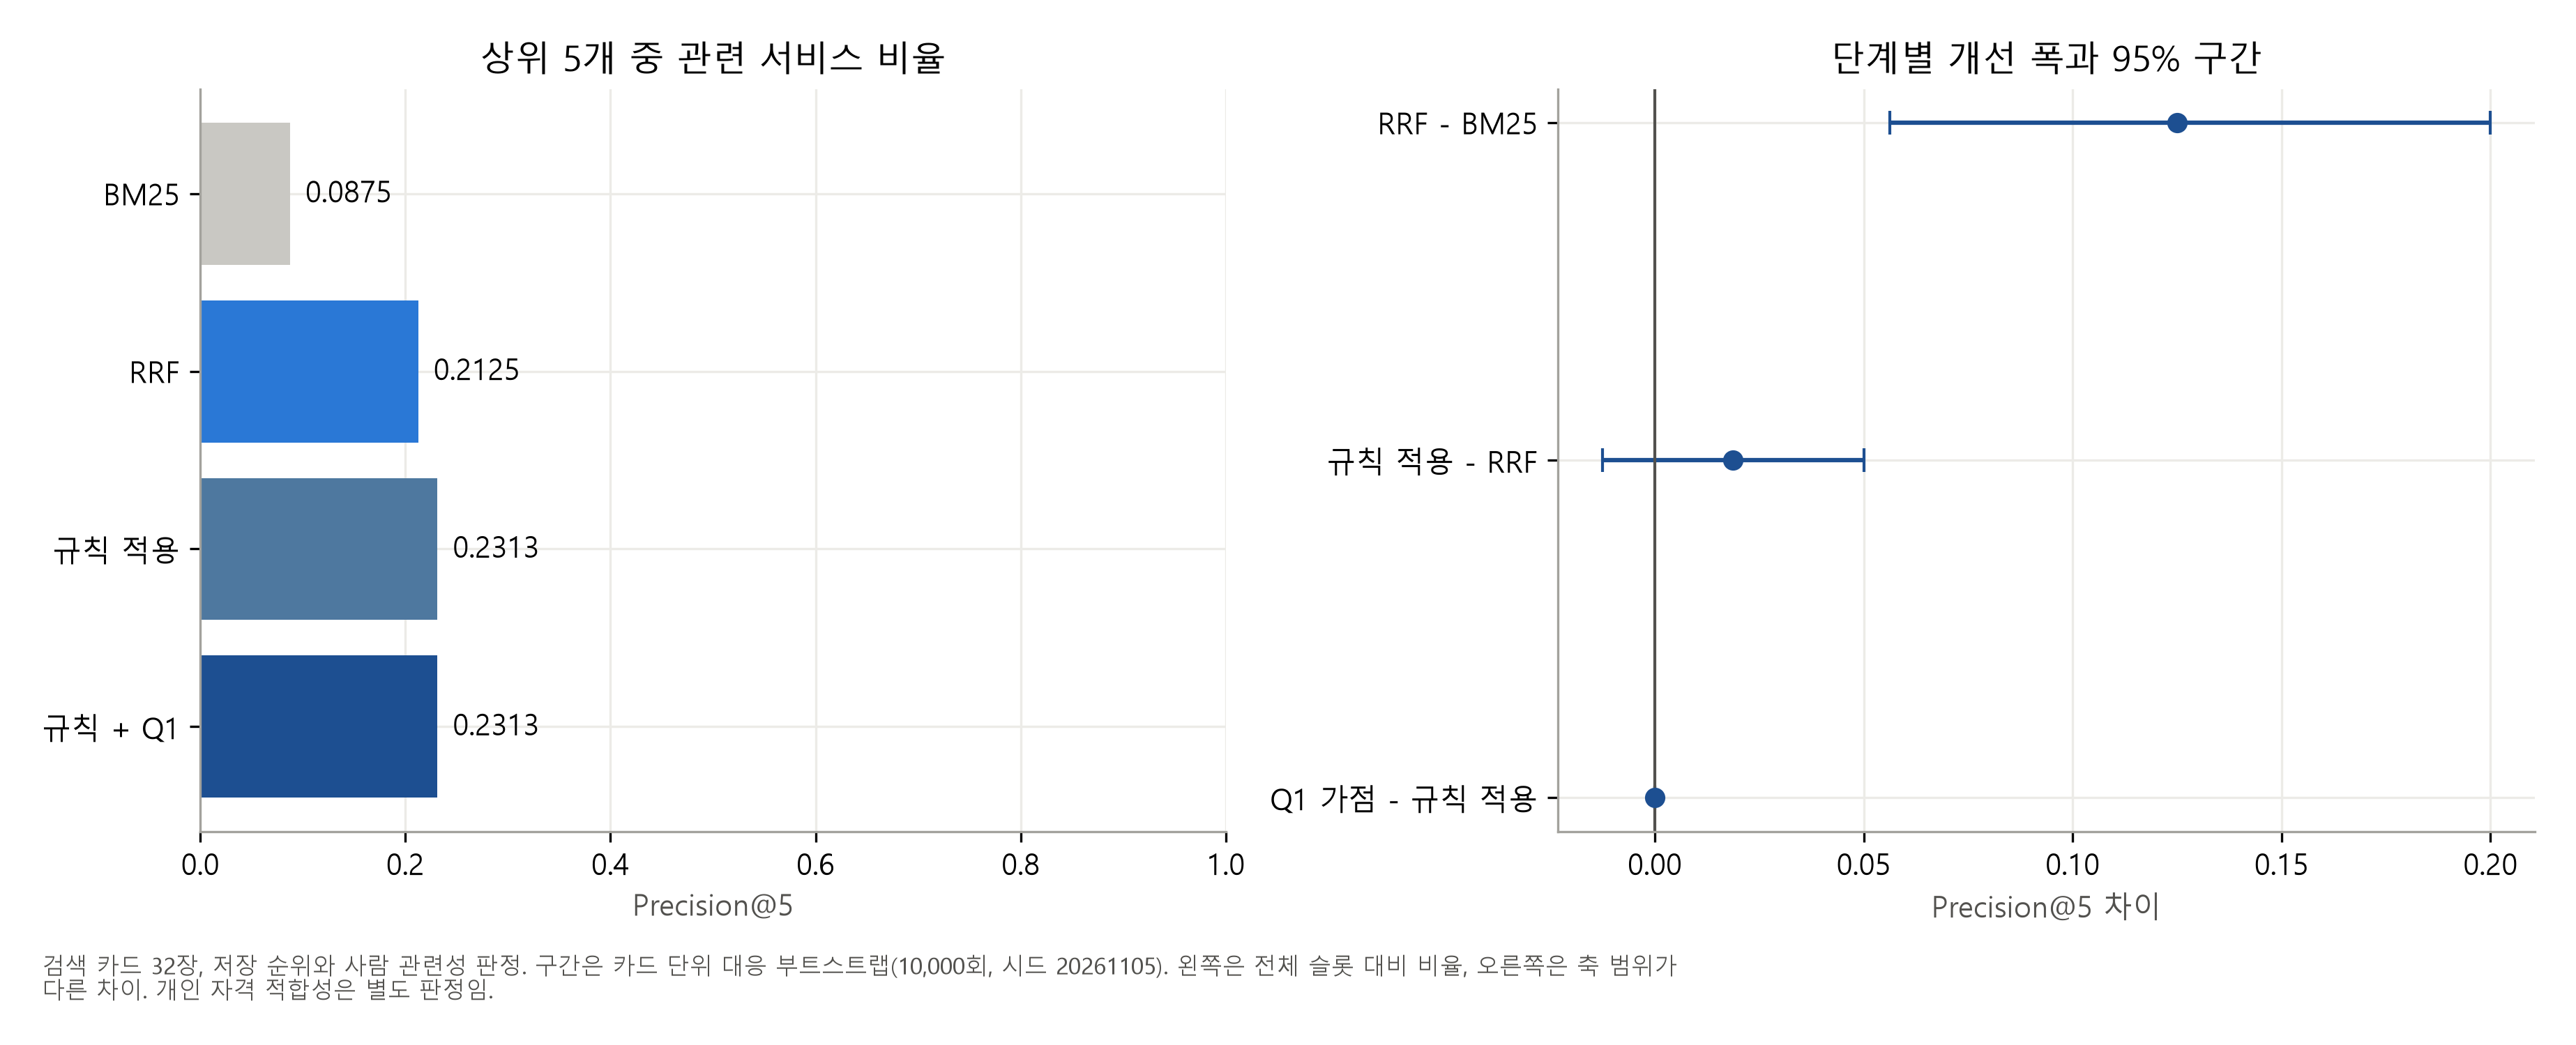

- 검색 결합의 개선과 이후 규칙·가점의 개선 폭을 구분해 확인함
- 위기 판단·욕구 추출·추천의 개선은 이후 평가에서 같은 지표와 표본 조건으로 확인할 필요가 있음

In [18]:
if rank_file.is_file() and subset_file.is_file():
    paired_plot = paired.loc[
        (paired["arm_a"].eq("bm25") & paired["arm_b"].eq("rrf")) |
        (paired["arm_a"].eq("rrf") & paired["arm_b"].eq("rules_q1off")) |
        (paired["arm_a"].eq("rules_q1off") & paired["arm_b"].eq("recommendation"))
    ].copy()
    save_table(paired_plot, "q3_precision_improvements.csv")
    names = ["RRF - BM25", "규칙 적용 - RRF", "Q1 가점 - 규칙 적용"]
    fig, (left, right) = plt.subplots(
        1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.05, 1]}, layout="constrained"
    )
    positions = np.arange(len(summary))
    left.barh(positions, summary["Precision@5"], color=[C_GRAY, C_MID, "#4e789f", C_DARK])
    left.set_yticks(positions, ["BM25", "RRF", "규칙 적용", "규칙 + Q1"])
    left.invert_yaxis()
    left.set(xlim=(0, 1), xlabel="Precision@5", title="상위 5개 중 관련 서비스 비율")
    for position, value in zip(positions, summary["Precision@5"]):
        left.text(value + .015, position, f"{value:.4f}", va="center", fontsize=10)
    diff = paired_plot["mean_diff"].to_numpy()
    lower = paired_plot["ci95_lo"].to_numpy()
    upper = paired_plot["ci95_hi"].to_numpy()
    right.errorbar(diff, np.arange(len(diff)), xerr=[diff - lower, upper - diff],
                   fmt="o", color=C_DARK, capsize=4, markersize=6)
    right.axvline(0, color=INK2, linewidth=1)
    right.set_yticks(range(len(diff)), names)
    right.invert_yaxis()
    right.set(xlabel="Precision@5 차이", title="단계별 개선 폭과 95% 구간")
    save_figure(fig, "q3_precision_comparison.png",
                f"검색 카드 {scores['card_id'].nunique()}장, 저장 순위와 사람 관련성 판정. "
                f"구간은 카드 단위 대응 부트스트랩({Q3.q3_eval.BOOTSTRAP_N:,}회, 시드 {Q3.q3_eval.SEED}). "
                "왼쪽은 전체 슬롯 대비 비율, 오른쪽은 축 범위가 다른 차이. 개인 자격 적합성은 별도 판정임.")
    display(Markdown(
        "- 검색 결합의 개선과 이후 규칙·가점의 개선 폭을 구분해 확인함\n"
        "- 위기 판단·욕구 추출·추천의 개선은 이후 평가에서 같은 지표와 표본 조건으로 확인할 필요가 있음"
    ))

- 사람 판정은 서비스의 지원내용이 요청에 도움이 되는지 확인한 것이며, 개인 자격은 별도로 확인함
- Kanana 모델을 포함한 전체 처리 과정은 위기 판단·정보 추출·검색을 잇는 가상 상황 평가로 추가 점검함
- 실제 청년과 복지 실무자를 대상으로 사용성과 안내 이해도를 확인할 필요가 있음

# 7. 종합 결과와 해석 범위

## 결론

- 지원 희망과 비대면 서비스 후보가 함께 확인되지만, 정보 인지·접근 경로·언어의 격차로 연결이 막힐 가능성이 있음
- 「반 걸음」은 일상어에서 출발해 외출 부담이 낮은 서비스와 원문 근거를 보여주고, 위기에는 전문기관 경로를 우선하는 모델임

## 기대효과

- **당사자** — 집에서 자기 말로 시작할 수 있는 첫 지원 경로를 확보함
- **복지 현장** — 비대면 1차 연결을 제공하고, 당사자 동의 시 상황 요약을 활용해 첫 상담의 부담을 줄일 수 있음
- **정책·데이터** — 비식별 집계로 비대면 선택지가 부족한 영역·지역을 탐색하고, 신청 채널과 대면 여부를 표준 항목으로 만드는 데 활용할 수 있음

## 한계와 향후 과제

- 수요 조사와 공급 자료는 시점·단위가 달라 개인에게 실제로 공급이 충분한지 직접 측정하기 어려움
- 라벨은 API 기록에 의존하며 명시적으로 판정할 수 없는 서비스와 실제 신청 절차의 인증·서류 부담이 남아 있음
- 모델의 욕구 추출·검색어 생성·추천 성능 개선을 진행 중이며, 현재 결과는 해당 평가 시점의 성능임
- 추천 자격 판정과 단계별 개선 효과를 추가 검증하고, 청년용 화면을 현장 실무자·당사자와 점검할 필요가 있음
- 이후 고립 중장년·가족돌봄청년으로 적용 범위를 넓히고 시군구별 비대면 접근 공백 지표를 검토함

# 부록. 분류 기준을 보완하면 결과가 어떻게 달라지는가

- 논문에 사용한 분류와 이후 보완한 분류를 같은 수집 자료에서 비교함
- 청년 대상 범위와 비대면 판단 기준이 달라지면 포함되는 서비스와 비율의 분모가 함께 달라짐
- 가정 방문과 대리 신청처럼 본인의 외출과 사람을 만나는 부담이 다른 경우를 구분함
- 기존 청년 집단을 고정한 비교를 함께 제시해 분류 기준의 영향을 확인함

In [19]:
assert current["servId"].is_unique and set(current["servId"]) == set(paper_master["servId"])

versions = pd.concat([
    access.assign(자료="논문 기준"),
    access_summary(current, "elig_youth_v1").assign(자료="개정 라벨·기존 청년 집단"),
    access_summary(current, "elig_youth").assign(자료="개정 라벨·개정 청년 집단"),
], ignore_index=True)
versions = versions.loc[
    versions["집단"].isin(["전체", "청년 대상"])
    & ~(versions["집단"].eq("전체") & versions["자료"].eq("개정 라벨·기존 청년 집단"))
]
show_versions = ["자료", "집단", "서비스 수", "방문·면접(%)", "온라인(%)",
                 "비대면 판정 가능", "비대면 완결", "비대면 완결(%)"]
save_table(versions[show_versions], "access_label_versions.csv")
display(versions[show_versions].round(precision).reset_index(drop=True))

,자료,집단,서비스 수,방문·면접(%),온라인(%),비대면 판정 가능,비대면 완결,비대면 완결(%)
0,논문 기준,전체,5288,58.8,29.7,3727,1255,33.7
1,논문 기준,청년 대상,608,44.2,48.4,514,250,48.6
2,개정 라벨·기존 청년 집단,청년 대상,608,44.2,42.7,517,196,37.9
3,개정 라벨·개정 청년 집단,전체,5288,58.9,27.3,3766,994,26.4
4,개정 라벨·개정 청년 집단,청년 대상,661,45.9,40.8,558,198,35.5
